# Prédiction du rendement agricole — Projet MLOps (T0 / V1)

**Notebook Kaggle adapté en français.** Ce projet préserve les 9 étapes demandées et ajoute les scripts et artefacts réutilisables. Le notebook original complet figure **en annexe**, avec ses cellules de code conservées. **Ne pas exécuter l'annexe après ce pipeline** : elle représente l'expérience Kaggle historique et peut contenir des traitements effectués avant la séparation des données.

**Important :** `Yield` est une cible continue : il s'agit d'une **régression**. Les métriques adaptées sont R², MAE et RMSE. Le score annoncé dans le titre du notebook source n'est pas une garantie de performance de ce pipeline. Les fichiers seront générés lors de l'exécution avec le CSV original.

## Étape 0 — Initialisation et chargement du dataset

Le CSV attendu est `data/crop_yield.csv` dans le dossier de projet Windows existant. Si le notebook est lancé sur Kaggle, le chemin Kaggle est également reconnu. Tous les chemins de sortie sont relatifs à `ROOT`.

In [16]:
from pathlib import Path
import os, sys, json, shutil, hashlib, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path(r"C:\Users\Hp\Desktop\Projet_MLOps_Churn")
if not ROOT.exists():
    ROOT = Path.cwd()
DATASET_CANDIDATES = [ROOT / 'data' / 'crop_yield.csv', Path('/kaggle/input/crop-yield-in-indian-states-dataset/crop_yield.csv')]
DATASET_PATH = next((p for p in DATASET_CANDIDATES if p.is_file()), None)
if DATASET_PATH is None:
    raise FileNotFoundError('Place le dataset crop_yield.csv dans ROOT/data/ puis relance cette cellule.')
for d in ['data','src','models','references','notebooks','reports/distributions_T0','reports/exploration_train','reports/evaluation_v1']:
    (ROOT/d).mkdir(parents=True, exist_ok=True)
RAW = pd.read_csv(DATASET_PATH)
print('Projet :',ROOT,'\nDataset :',DATASET_PATH,'\nDimensions :',RAW.shape)
display(RAW.head())

Projet : C:\Users\Hp\Desktop\Projet_MLOps_Churn 
Dataset : C:\Users\Hp\Desktop\Projet_MLOps_Churn\data\crop_yield.csv 
Dimensions : (19689, 10)


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


## Étape 1 — Nettoyage des données

**Rôle :** garantir la qualité des observations. Les règles sont partagées entre le nettoyage d'entraînement et la validation de production : normalisation des catégories, types numériques, rejet des cibles absentes, contrôles de plausibilité. Les valeurs manquantes des variables explicatives restent présentes pour être imputées **après** le split. Le notebook Kaggle original normalise `Crop`, `State`, `Season` et écarte 2020 ; ici, l'exclusion de 2020 est **optionnelle**, car elle doit être justifiée pour la surveillance temporelle.

In [37]:

# ============================================================
# NETTOYAGE DU DATASET ET VÉRIFICATION
# SUPPRESSION DE PRODUCTION POUR ÉVITER LA FUITE DE DONNÉES
# ============================================================

import sys
from pathlib import Path

# ------------------------------------------------------------
# 1. CONFIGURATION DES CHEMINS
# ------------------------------------------------------------

ROOT = Path(r"C:\Users\Hp\Desktop\Projet_MLOps_Churn")

sys.path.insert(0, str(ROOT / "src"))

# ------------------------------------------------------------
# 2. IMPORTATION DES FONCTIONS
# ------------------------------------------------------------

from nettoyage_dataset import (
    nettoyer_dataset,
    nettoyer_features,
    FEATURES,
    TARGET,
    NUMERIC,
    CATEGORICAL
)

from nettoyage_production import nettoyer_production

# ------------------------------------------------------------
# 3. NETTOYAGE DU DATASET
# ------------------------------------------------------------

clean = nettoyer_dataset(RAW)

# ------------------------------------------------------------
# 4. SUPPRESSION DE LA COLONNE PRODUCTION
# ------------------------------------------------------------

# Supprimer Production des données nettoyées
clean = clean.drop(
    columns=["Production"],
    errors="ignore"
)

# Définir les variables explicatives sans Production
FEATURES_SANS_PRODUCTION = [
    colonne for colonne in FEATURES
    if colonne != "Production"
]

NUMERIC_SANS_PRODUCTION = [
    colonne for colonne in NUMERIC
    if colonne != "Production"
]

# ------------------------------------------------------------
# 5. ORGANISATION DES COLONNES
# ------------------------------------------------------------

clean = clean[
    FEATURES_SANS_PRODUCTION + [TARGET]
]

# ------------------------------------------------------------
# 6. SAUVEGARDE DU DATASET NETTOYÉ
# ------------------------------------------------------------

chemin_clean = ROOT / "data" / "dataset_clean.csv"

chemin_clean.parent.mkdir(
    parents=True,
    exist_ok=True
)

clean.to_csv(
    chemin_clean,
    index=False
)

# ------------------------------------------------------------
# 7. VÉRIFICATIONS
# ------------------------------------------------------------

assert "Production" not in clean.columns, (
    "Erreur : Production est encore présente."
)

assert TARGET in clean.columns, (
    "Erreur : la variable cible Yield est absente."
)

assert clean.columns.tolist() == (
    FEATURES_SANS_PRODUCTION + [TARGET]
)

# ------------------------------------------------------------
# 8. AFFICHAGE DES RÉSULTATS
# ------------------------------------------------------------

print("=" * 60)
print("NETTOYAGE DU DATASET — SANS PRODUCTION")
print("=" * 60)

print("\nDimensions :")
print("Avant :", RAW.shape)
print("Après :", clean.shape)

print("\nVariables explicatives :")
print(FEATURES_SANS_PRODUCTION)

print("\nVariables numériques :")
print(NUMERIC_SANS_PRODUCTION)

print("\nVariables catégorielles :")
print(CATEGORICAL)

print("\nVariable cible :", TARGET)

print("\nValeurs manquantes par colonne :")
display(
    clean.isna().sum().to_frame("Manquantes")
)

print("\nFichier sauvegardé :")
print(chemin_clean)


NETTOYAGE DU DATASET — SANS PRODUCTION

Dimensions :
Avant : (19689, 10)
Après : (19689, 9)

Variables explicatives :
['Crop', 'Season', 'State', 'Crop_Year', 'Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']

Variables numériques :
['Crop_Year', 'Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']

Variables catégorielles :
['Crop', 'Season', 'State']

Variable cible : Yield

Valeurs manquantes par colonne :


,Manquantes
Crop,0
Season,0
State,0
Crop_Year,0
Area,0
Annual_Rainfall,0
Fertilizer,0
Pesticide,0
Yield,0



Fichier sauvegardé :
C:\Users\Hp\Desktop\Projet_MLOps_Churn\data\dataset_clean.csv


Génération et vérification des scripts de nettoyage : 


In [ ]:

# ============================================================
# GÉNÉRATION DES SCRIPTS DE NETTOYAGE TRAIN / PRODUCTION
# SANS LA VARIABLE PRODUCTION (RISQUE DE FUITE DE DONNÉES)
# Validation des types + maximum 3 champs manquants
# ============================================================

from pathlib import Path
from textwrap import dedent
import sys
import importlib
import pandas as pd

# ------------------------------------------------------------
# 1. CHEMINS DU PROJET
# ------------------------------------------------------------

ROOT = Path(r"C:\Users\Hp\Desktop\Projet_MLOps_Churn")

SRC_PATH = ROOT / "src"
SRC_PATH.mkdir(parents=True, exist_ok=True)

NETTOYAGE_PATH = SRC_PATH / "nettoyage_dataset.py"
PRODUCTION_PATH = SRC_PATH / "nettoyage_production.py"

# ------------------------------------------------------------
# 2. SCRIPT COMMUN DE NETTOYAGE
# ------------------------------------------------------------

nettoyage_source = dedent("""
import pandas as pd
import numpy as np

TARGET = "Yield"

# Production supprimée des variables explicatives
NUMERIC = [
    "Crop_Year",
    "Area",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide"
]

CATEGORICAL = [
    "Crop",
    "Season",
    "State"
]

FEATURES = CATEGORICAL + NUMERIC
REQUIRED = FEATURES + [TARGET]


def nettoyer_features(df):
    '''
    Règles communes Train / Production.
    Les valeurs non conformes deviennent NaN.
    Aucune observation supprimée ici.
    La variable Production n'est pas utilisée.
    '''

    d = df.copy()

    for c in FEATURES:
        if c not in d.columns:
            d[c] = pd.NA

    # Variables catégorielles
    for c in CATEGORICAL:
        d[c] = (
            d[c]
            .astype("string")
            .str.strip()
            .str.title()
            .replace("", pd.NA)
        )

    # Variables numériques
    for c in NUMERIC:
        d[c] = pd.to_numeric(
            d[c], errors="coerce"
        )

        d[c] = d[c].replace(
            [np.inf, -np.inf], np.nan
        )

    # Valeurs négatives interdites
    for c in [
        "Area",
        "Annual_Rainfall",
        "Fertilizer",
        "Pesticide"
    ]:
        d.loc[d[c] < 0, c] = np.nan

    # Année entière entre 1900 et 2100
    annee = d["Crop_Year"]

    d.loc[
        (annee < 1900) |
        (annee > 2100) |
        ((annee % 1) != 0),
        "Crop_Year"
    ] = np.nan

    return d[FEATURES].copy()


def nettoyer_dataset(df):
    '''
    Nettoyage historique du dataset avec Yield.
    Production est exclue des données finales.
    '''

    d = df.copy()

    if TARGET not in d.columns:
        raise ValueError(
            "La colonne Yield est absente."
        )

    # Supprimer les doublons historiques
    d = d.drop_duplicates().copy()

    # Nettoyer les 8 variables explicatives
    x = nettoyer_features(d)

    # Nettoyer la variable cible
    y = pd.to_numeric(
        d[TARGET], errors="coerce"
    )

    y = y.replace(
        [np.inf, -np.inf], np.nan
    )

    # Conserver les observations valides
    ok = (
        y.notna() &
        (y >= 0) &
        x.notna().any(axis=1)
    )

    result = x.loc[ok].copy()
    result[TARGET] = y.loc[ok].astype(float)

    return result.reset_index(drop=True)
""")

NETTOYAGE_PATH.write_text(
    nettoyage_source.strip() + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 3. SCRIPT DE VALIDATION EN PRODUCTION
# ------------------------------------------------------------

production_source = dedent("""
import pandas as pd
import numpy as np

from numbers import Real

from nettoyage_dataset import (
    FEATURES,
    CATEGORICAL,
    NUMERIC,
    nettoyer_features
)

MAX_MANQUANTS = 3

FORMATS_ATTENDUS = {
    "Crop": "Texte non vide, ex. Rice",
    "Season": "Texte non vide, ex. Kharif",
    "State": "Texte non vide, ex. Assam",
    "Crop_Year": "Année entière entre 1900 et 2100",
    "Area": "Nombre positif ou nul, ex. 150",
    "Annual_Rainfall": "Nombre positif ou nul, ex. 1200",
    "Fertilizer": "Nombre positif ou nul, ex. 200",
    "Pesticide": "Nombre positif ou nul, ex. 15"
}


def est_manquant(valeur):
    '''
    Détecter un champ réellement absent.
    '''

    if valeur is None:
        return True

    if isinstance(valeur, str):
        return valeur.strip() == ""

    if isinstance(valeur, (list, dict, tuple, set)):
        return False

    try:
        resultat = pd.isna(valeur)

        if isinstance(resultat, (bool, np.bool_)):
            return bool(resultat)

    except (TypeError, ValueError):
        pass

    return False


def valider_champ(champ, valeur):
    '''
    Retourne :
    - manquant : champ absent
    - valide : valeur conforme
    - invalide : mauvais type ou mauvaise valeur
    '''

    if est_manquant(valeur):
        return "manquant"

    # Variables catégorielles
    if champ in CATEGORICAL:

        if not isinstance(valeur, str):
            return "invalide"

        return "valide"

    # Variables numériques
    if isinstance(valeur, (bool, np.bool_)):
        return "invalide"

    if not isinstance(valeur, (str, Real, np.number)):
        return "invalide"

    try:
        nombre = float(valeur)

    except (ValueError, TypeError, OverflowError):
        return "invalide"

    if not np.isfinite(nombre):
        return "invalide"

    # Vérification de l'année
    if champ == "Crop_Year":

        if not nombre.is_integer():
            return "invalide"

        if not (1900 <= nombre <= 2100):
            return "invalide"

        return "valide"

    # Autres variables numériques positives ou nulles
    if champ in NUMERIC:

        if nombre < 0:
            return "invalide"

        return "valide"

    return "invalide"


def nettoyer_production(df):
    '''
    Validation et nettoyage des données de production.

    Une observation est acceptée si :
    - aucun champ renseigné n'est invalide
    - au maximum 3 champs sont manquants

    Production n'est pas une variable attendue.

    Retour :
        donnees_valides, avertissements
    '''

    donnees_brutes = df.copy()

    # Compléter les colonnes absentes
    for champ in FEATURES:

        if champ not in donnees_brutes.columns:
            donnees_brutes[champ] = pd.NA

    # Nettoyage commun Train / Production
    donnees_nettoyees = nettoyer_features(
        donnees_brutes
    )

    lignes_acceptees = []
    avertissements = []

    for position in range(len(donnees_brutes)):

        ligne = donnees_brutes.iloc[position]

        champs_manquants = []
        champs_invalides = []

        # Vérifier chaque champ
        for champ in FEATURES:

            statut = valider_champ(
                champ,
                ligne[champ]
            )

            if statut == "manquant":
                champs_manquants.append(champ)

            elif statut == "invalide":
                champs_invalides.append(champ)

        nombre_manquants = len(champs_manquants)

        # Observation acceptée
        if (
            len(champs_invalides) == 0
            and nombre_manquants <= MAX_MANQUANTS
        ):
            lignes_acceptees.append(position)
            continue

        # Observation refusée
        formats_a_corriger = {
            champ: FORMATS_ATTENDUS[champ]
            for champ in champs_invalides
        }

        if nombre_manquants > MAX_MANQUANTS:

            for champ in champs_manquants:
                formats_a_corriger[champ] = (
                    FORMATS_ATTENDUS[champ]
                )

        motifs = []

        if champs_invalides:
            motifs.append(
                "Certains champs ne respectent pas "
                "le type ou le format attendu."
            )

        if nombre_manquants > MAX_MANQUANTS:
            motifs.append(
                "Plus de 3 champs sont manquants."
            )

        avertissements.append({
            "ligne": position,
            "nombre_manquants": nombre_manquants,
            "champs_manquants": champs_manquants,
            "champs_invalides": champs_invalides,
            "message": (
                " ".join(motifs) +
                " Veuillez corriger votre saisie."
            ),
            "formats_attendus": formats_a_corriger
        })

    # Conserver les observations acceptées
    donnees_valides = donnees_nettoyees.iloc[
        lignes_acceptees
    ].copy()

    return donnees_valides, avertissements
""")

PRODUCTION_PATH.write_text(
    production_source.strip() + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 4. IMPORT ET RECHARGEMENT DES SCRIPTS
# ------------------------------------------------------------

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

importlib.invalidate_caches()

import nettoyage_dataset
import nettoyage_production

importlib.reload(nettoyage_dataset)
importlib.reload(nettoyage_production)

from nettoyage_dataset import (
    nettoyer_dataset,
    nettoyer_features,
    FEATURES,
    TARGET,
    NUMERIC,
    CATEGORICAL
)

from nettoyage_production import (
    nettoyer_production,
    MAX_MANQUANTS
)

# ------------------------------------------------------------
# 5. TEST AUTOMATIQUE EN PRODUCTION
# ------------------------------------------------------------

exemples = pd.DataFrame([

    # Cas 1 : toutes les valeurs valides
    {
        "Crop": "Rice",
        "Season": "Kharif",
        "State": "Assam",
        "Crop_Year": 2024,
        "Area": 150,
        "Annual_Rainfall": 1200,
        "Fertilizer": 200,
        "Pesticide": 15
    },

    # Cas 2 : trois valeurs manquantes
    {
        "Crop": "Rice",
        "Season": "Kharif",
        "State": "Assam",
        "Crop_Year": 2024,
        "Area": None,
        "Annual_Rainfall": None,
        "Fertilizer": 200,
        "Pesticide": None
    },

    # Cas 3 : type invalide
    {
        "Crop": "Rice",
        "Season": "Kharif",
        "State": "Assam",
        "Crop_Year": "bonjour",
        "Area": 150,
        "Annual_Rainfall": 1200,
        "Fertilizer": 200,
        "Pesticide": 15
    },

    # Cas 4 : valeur négative invalide
    {
        "Crop": "Rice",
        "Season": "Kharif",
        "State": "Assam",
        "Crop_Year": 2024,
        "Area": -100,
        "Annual_Rainfall": 1200,
        "Fertilizer": 200,
        "Pesticide": 15
    },

    # Cas 5 : quatre champs manquants
    {
        "Crop": "Rice",
        "Season": "Kharif",
        "State": "Assam",
        "Crop_Year": 2024,
        "Area": None,
        "Annual_Rainfall": None,
        "Fertilizer": None,
        "Pesticide": None
    }

])

donnees_valides, avertissements = nettoyer_production(
    exemples
)

# ------------------------------------------------------------
# 6. VÉRIFICATIONS AUTOMATIQUES
# ------------------------------------------------------------

assert len(FEATURES) == 8
assert "Production" not in FEATURES
assert "Production" not in NUMERIC

assert len(donnees_valides) == 2
assert len(avertissements) == 3

assert donnees_valides.isna().sum(axis=1).max() <= 3
assert donnees_valides.columns.tolist() == FEATURES

print("=" * 65)
print("TEST DU NETTOYAGE EN PRODUCTION — SANS PRODUCTION")
print("=" * 65)

print("\nObservations testées :", len(exemples))
print("Observations acceptées :", len(donnees_valides))
print("Observations refusées :", len(avertissements))

print("\nDONNÉES ACCEPTÉES :")
display(donnees_valides)

print("\nAVERTISSEMENTS :")

for avertissement in avertissements:

    print("\nLigne :", avertissement["ligne"])
    print(avertissement["message"])

    print(
        "Champs invalides :",
        avertissement["champs_invalides"]
    )

    print(
        "Champs manquants :",
        avertissement["champs_manquants"]
    )

    print("Formats attendus :")

    for champ, format_attendu in (
        avertissement["formats_attendus"].items()
    ):
        print(f"  - {champ} : {format_attendu}")

# ------------------------------------------------------------
# 7. BILAN
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SCRIPTS GÉNÉRÉS AVEC SUCCÈS")
print("=" * 65)

print("\nFichier Train :", NETTOYAGE_PATH)
print("Fichier Production :", PRODUCTION_PATH)

print("\nVariables explicatives :", FEATURES)
print("Nombre de variables :", len(FEATURES))
print("Variable cible :", TARGET)

print("\nRègles :")
print("- Production exclue des variables explicatives")
print("- 0 à 3 champs manquants : acceptés")
print("- 4 à 8 champs manquants : refusés")
print("- Tout champ renseigné invalide : refusé")
print("- Avertissement avec les formats attendus")
print("- Nettoyage commun Train / Production")

print("\nAucun dataset existant n'a été modifié.")


TEST DU NETTOYAGE EN PRODUCTION
Observations testées : 5
Observations acceptées : 2
Observations refusées : 3

DONNÉES ACCEPTÉES :


,Crop,Season,State,Crop_Year,Area,Production,Annual_Rainfall,Fertilizer,Pesticide
0,Rice,Kharif,Assam,2024.0,150.0,500.0,1200.0,200.0,15.0
1,Rice,Kharif,Assam,2024.0,NaN,500.0,NaN,200.0,NaN



AVERTISSEMENTS :

Ligne : 2
Certains champs ne respectent pas le type ou le format attendu. Veuillez corriger votre saisie.
Champs invalides : ['Crop_Year']
Champs manquants : []
Formats attendus :
  - Crop_Year : Année entière entre 1900 et 2100

Ligne : 3
Certains champs ne respectent pas le type ou le format attendu. Veuillez corriger votre saisie.
Champs invalides : ['Area']
Champs manquants : []
Formats attendus :
  - Area : Nombre positif ou nul, ex. 150

Ligne : 4
Plus de 3 champs sont manquants. Veuillez corriger votre saisie.
Champs invalides : []
Champs manquants : ['Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']
Formats attendus :
  - Area : Nombre positif ou nul, ex. 150
  - Annual_Rainfall : Nombre positif ou nul, ex. 1200
  - Fertilizer : Nombre positif ou nul, ex. 200
  - Pesticide : Nombre positif ou nul, ex. 15

SCRIPTS GÉNÉRÉS AVEC SUCCÈS

Fichier Train : C:\Users\Hp\Desktop\Projet_MLOps_Churn\src\nettoyage_dataset.py
Fichier Production : C:\Users\Hp\Desktop\Pr

## Étape 2 — Répartition et sauvegarde des données

**Rôle :** isoler les données avant tout ajustement de transformations. Pour une **régression**, il n'existe pas de classes à stratifier ; on utilise ici des **quantiles de `Yield`** si leurs effectifs le permettent, sinon un découpage aléatoire reproductible. Les fractions sont 60 % Train, 10 % Validation, 10 % Test, 20 % Simulation. **Attention :** des observations de mêmes années peuvent se retrouver dans plusieurs ensembles ; pour une prévision chronologique réelle, préférer une validation temporelle.

In [21]:
(ROOT/'src/split_data.py').write_text("import pandas as pd\nfrom sklearn.model_selection import train_test_split\n\ndef strat_yield(df):\n    try:\n        bins = pd.qcut(df['Yield'], q=10, duplicates='drop')\n        if bins.nunique() >= 2 and bins.value_counts().min() >= 4:\n            return bins\n    except (ValueError, TypeError):\n        pass\n    return None\n\ndef partager(df, seed=42):\n    # 20% simulation, puis 10% test, puis 10% validation (du total)\n    trainvaltest, sim = train_test_split(df, test_size=.20, random_state=seed, stratify=strat_yield(df))\n    trainval, test = train_test_split(trainvaltest, test_size=.125, random_state=seed, stratify=strat_yield(trainvaltest))\n    train, val = train_test_split(trainval, test_size=1/7, random_state=seed, stratify=strat_yield(trainval))\n    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True), sim.reset_index(drop=True)\n",encoding='utf-8')
from split_data import partager
train, validation, test, simulation = partager(clean)
for name, frame in [('train',train),('validation',validation),('test',test),('simulation_T0',simulation)]:
    frame.to_csv(ROOT/'data'/f'{name}.csv',index=False)
    print(name, frame.shape, f'{len(frame)/len(clean):.1%}')
assert sum(map(len,[train,validation,test,simulation])) == len(clean)
# Contrôle de recouvrement par empreintes de lignes (hors duplications déjà présentes)
sets = [set(pd.util.hash_pandas_object(d, index=False).tolist()) for d in [train,validation,test,simulation]]
for i in range(4):
    for j in range(i+1,4):
        print(f'Intersection {i}/{j} :',len(sets[i]&sets[j]))

train (11813, 10) 60.0%
validation (1969, 10) 10.0%
test (1969, 10) 10.0%
simulation_T0 (3938, 10) 20.0%
Intersection 0/1 : 0
Intersection 0/2 : 0
Intersection 0/3 : 0
Intersection 1/2 : 0
Intersection 1/3 : 0
Intersection 2/3 : 0


Génération de : simulation_T0.csv    test.csv     train.csv    validation.csv  au niveau de data 


## Étape 3 — Statistiques de référence et visualisation des distributions sur Train (T0)

**Rôle :** calculer et conserver les statistiques descriptives et les distributions de l'ensemble d'entraînement, qui constitue la référence T0 du système MLOps.

Cette étape comprend :
- Le calcul des statistiques numériques : moyenne, médiane, variance, écart-type, quantiles, IQR, asymétrie, kurtosis et valeurs aberrantes.
- Le calcul des statistiques catégorielles : effectifs, proportions, mode et valeurs manquantes.
- La conservation des bornes et des fréquences des histogrammes.
- La génération des histogrammes, boxplots et diagrammes de fréquences.

Les statistiques et distributions T0 sont calculées exclusivement sur Train. Les données de Validation, Test et Simulation ne sont pas utilisées.

Les mêmes fonctions pourront être appliquées ultérieurement aux données de production T1, afin de comparer leurs distributions avec celles de T0 et de détecter une éventuelle dérive des données.


Dataset de référence chargé : (11813, 10)


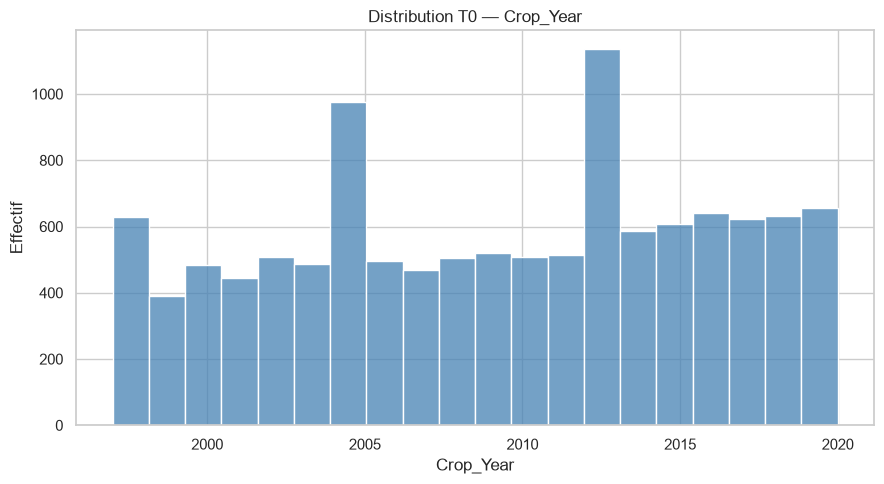

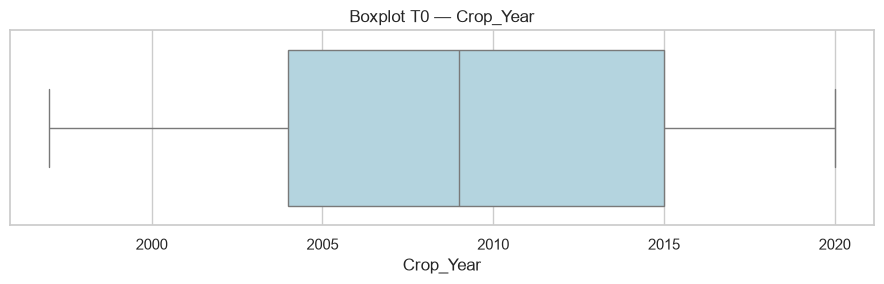

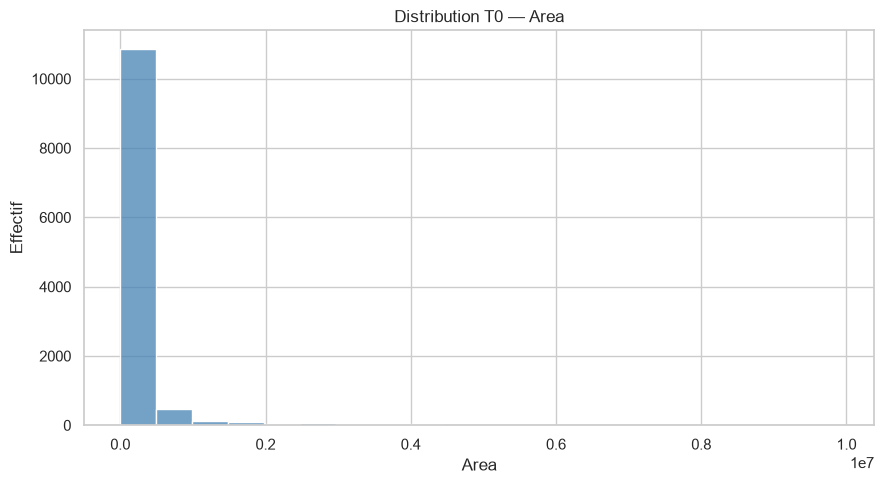

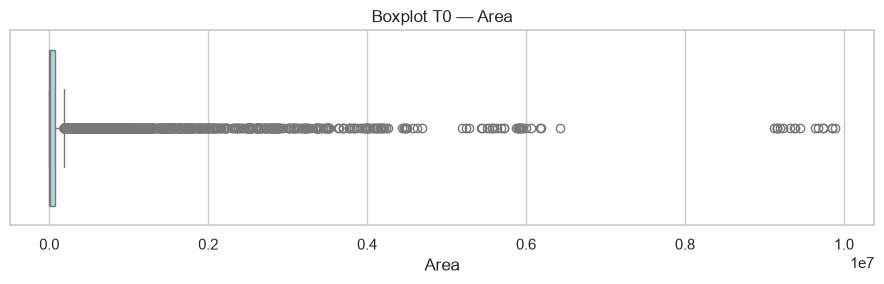

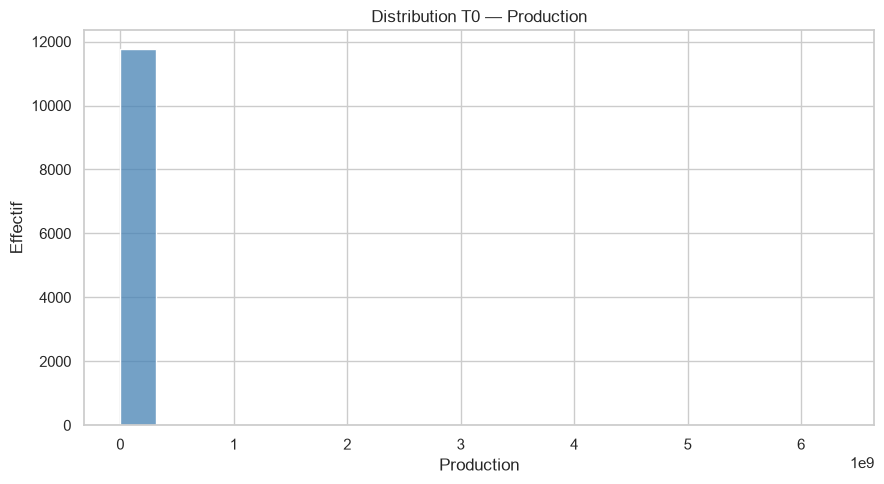

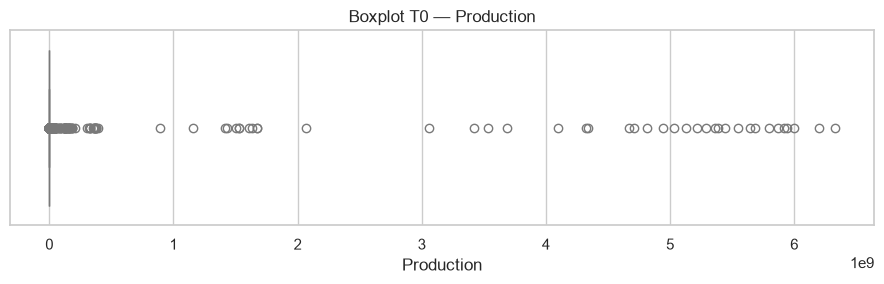

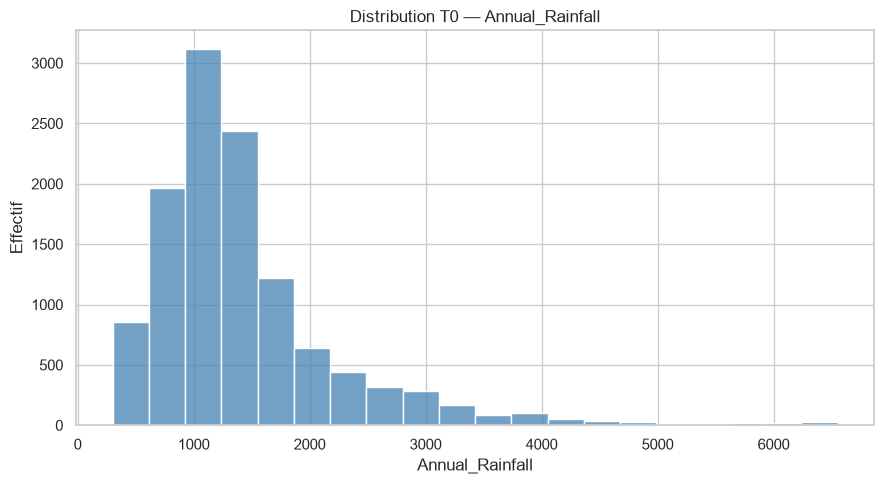

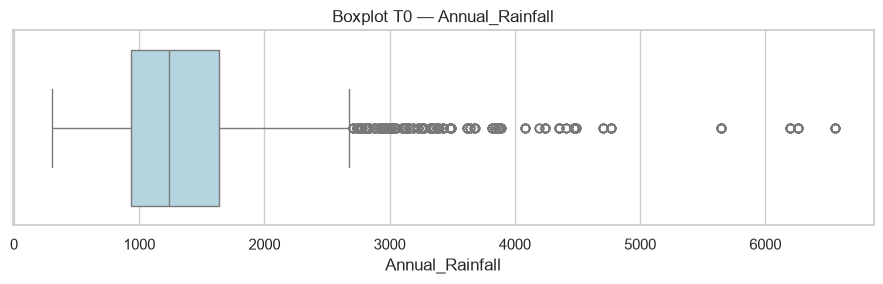

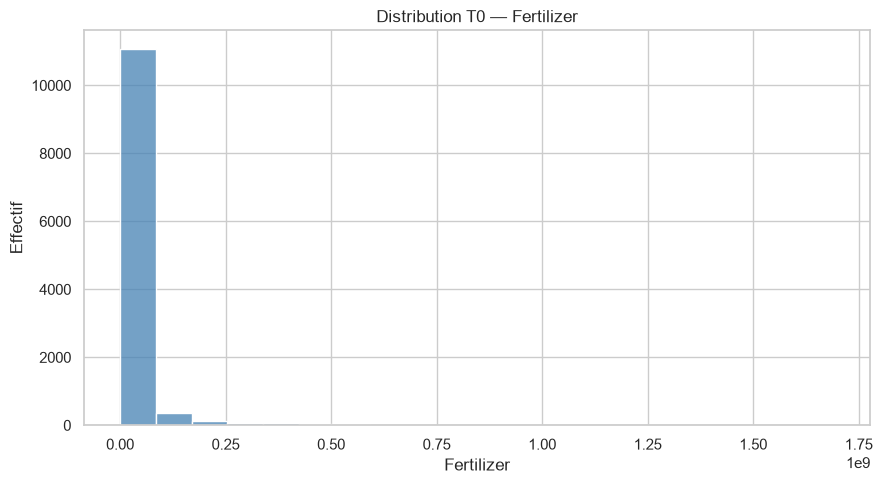

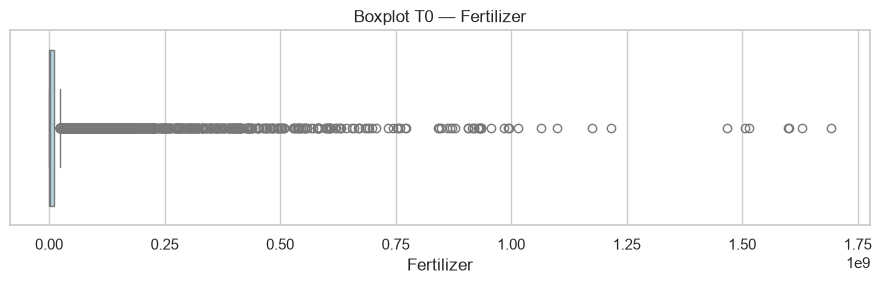

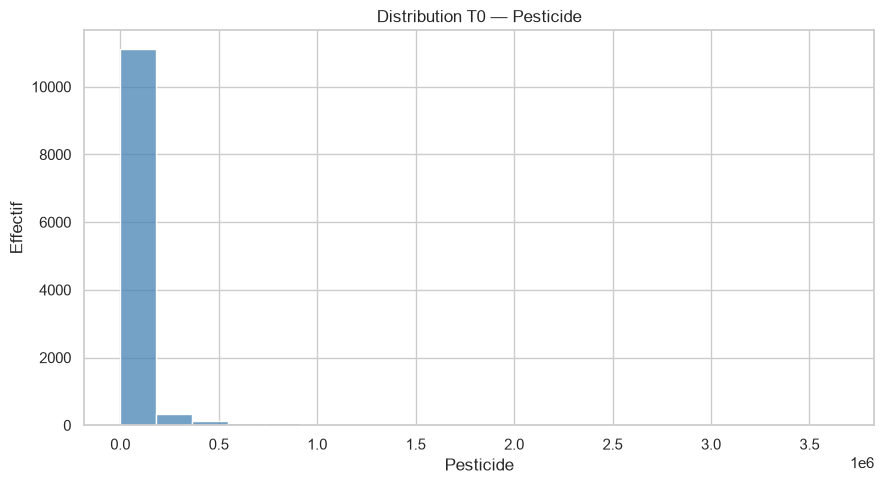

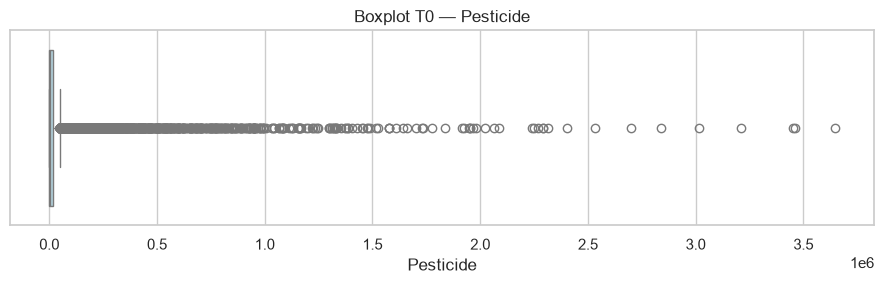

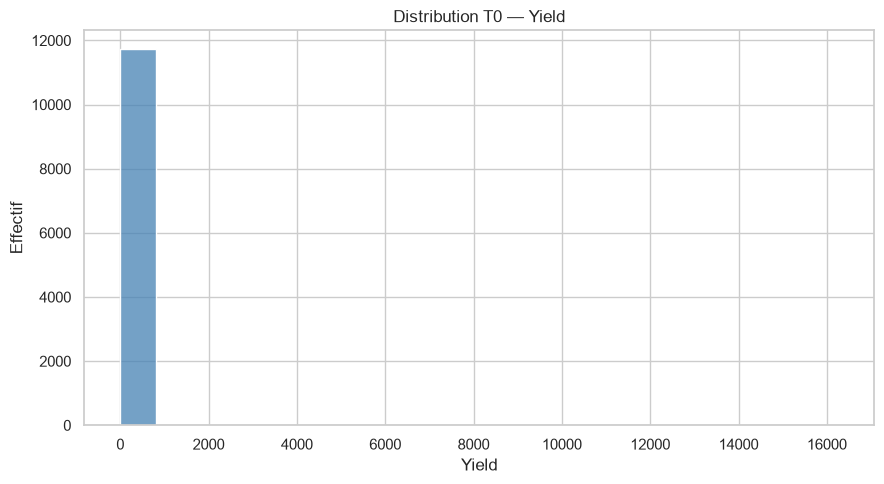

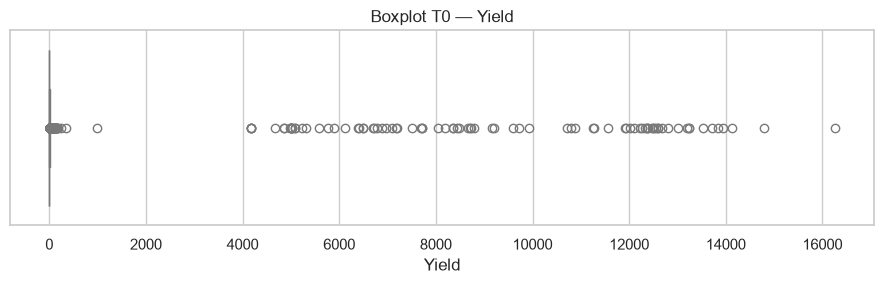

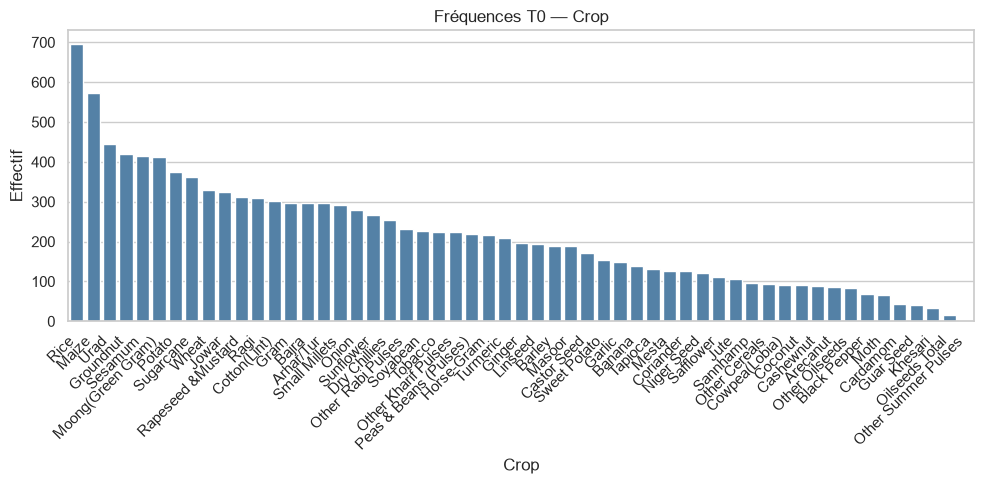

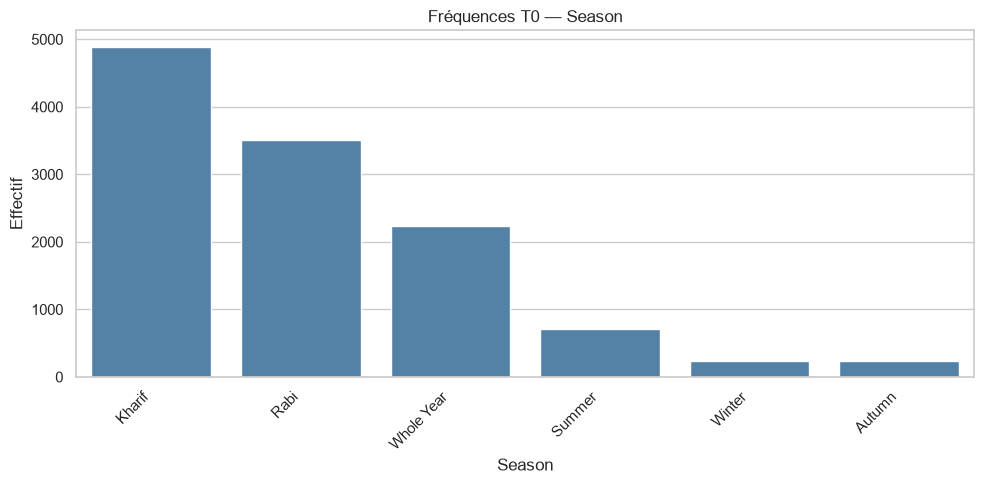

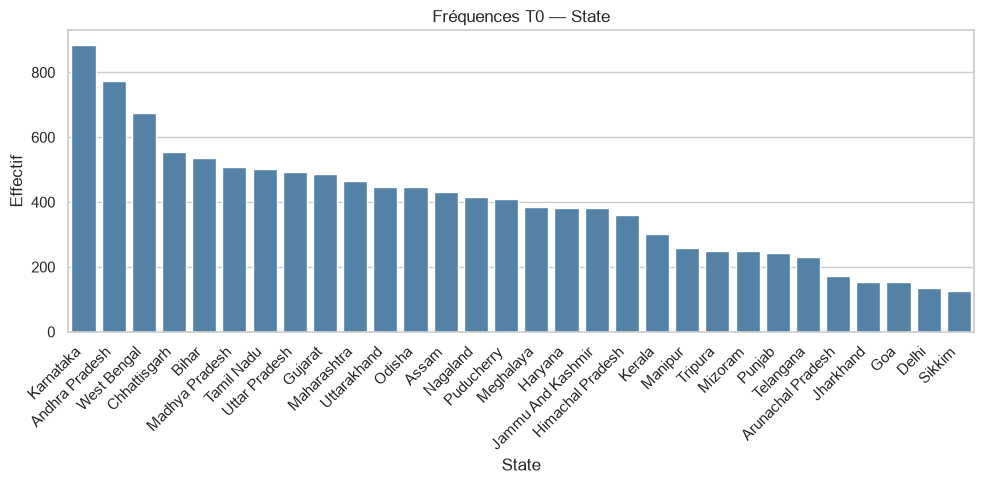


STATISTIQUES NUMÉRIQUES T0


,Variable,Effectif,Manquants,Moyenne,Médiane,Écart-type,Variance,Min,Max,IQR,Skewness,Kurtosis,Outliers IQR
0,Crop_Year,11813,0,2.009089e+03,2009.00,6.504000e+00,4.230000e+01,1997.00,2.020000e+03,11.000,-0.156,-1.185,0
1,Area,11813,0,1.809712e+05,9273.00,6.535859e+05,4.271745e+11,1.00,9.884913e+06,72520.000,7.680,79.034,1827
2,Production,11813,0,1.494292e+07,13300.00,2.541826e+08,6.460882e+16,0.00,6.326000e+09,119445.000,20.229,424.318,2020
3,Annual_Rainfall,11813,0,1.430027e+03,1238.50,8.156490e+02,6.652832e+05,301.30,6.552700e+03,702.700,2.165,7.233,893
4,Fertilizer,11813,0,2.429406e+07,1230996.69,8.993285e+07,8.087917e+15,94.67,1.692266e+09,9600750.960,8.131,91.475,1846
5,Pesticide,11813,0,4.888682e+04,2420.40,1.838094e+05,3.378590e+10,0.09,3.645426e+06,19136.252,8.330,96.074,1824
6,Yield,11813,0,7.181700e+01,1.03,8.273020e+02,6.844279e+05,0.00,1.625400e+04,1.798,13.350,187.884,1829



STATISTIQUES CATÉGORIELLES T0


,Variable,Manquants,Nombre catégories,Mode,Effectifs,Proportions
0,Crop,0,55,Rice,"{'Rice': 695, 'Maize': 573, 'Urad': 446, 'Grou...","{'Rice': 0.05883348852958605, 'Maize': 0.04850..."
1,Season,0,6,Kharif,"{'Kharif': 4886, 'Rabi': 3512, 'Whole Year': 2...","{'Kharif': 0.41361212223821214, 'Rabi': 0.2972..."
2,State,0,30,Karnataka,"{'Karnataka': 885, 'Andhra Pradesh': 774, 'Wes...","{'Karnataka': 0.07491746381105562, 'Andhra Pra..."



Exemple : statistiques de Yield
{
  "type": "float64",
  "effectif_total": 11813,
  "effectif_non_manquant": 11813,
  "manquants": 0,
  "taux_manquants": 0.0,
  "nombre_valeurs_uniques": 8788,
  "moyenne": 71.81697255016356,
  "mediane": 1.03,
  "variance": 684427.9031621978,
  "ecart_type": 827.3015793301726,
  "min": 0.0,
  "max": 16254.0,
  "etendue": 16254.0,
  "quartiles_quantiles": {
    "0.0": 0.0,
    "0.01": 0.088,
    "0.05": 0.25,
    "0.1": 0.3463703702,
    "0.25": 0.598,
    "0.5": 1.03,
    "0.75": 2.395555556,
    "0.9": 9.528909091000006,
    "0.95": 21.358284613999984,
    "0.99": 95.78919347559864,
    "1.0": 16254.0
  },
  "iqr": 1.7975555560000003,
  "skewness": 13.350224509804208,
  "kurtosis": 187.88352183835008,
  "borne_inferieure_iqr": -2.0983333340000003,
  "borne_superieure_iqr": 5.09188889,
  "nombre_outliers_iqr": 1829,
  "bornes_histogramme": [
    0.0,
    812.7,
    1625.4,
    2438.1000000000004,
    3250.8,
    4063.5,
    4876.200000000001,
    5688

In [22]:

# ============================================================
# ÉTAPE 3 : STATISTIQUES ET DISTRIBUTIONS DE RÉFÉRENCE T0
# ============================================================

from pathlib import Path
import json
import shutil
import importlib.util
from textwrap import dedent

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. CHEMINS DU PROJET
# ------------------------------------------------------------

ROOT = Path(r"C:\Users\Hp\Desktop\Projet_MLOps_Churn")

TRAIN_PATH = ROOT / "data" / "train.csv"
SCRIPT_PATH = ROOT / "src" / "calcul_statistiques.py"
STATS_PATH = ROOT / "references" / "statistiques_train.json"
REFERENCE_PATH = ROOT / "references" / "train.csv"
FIGURES_PATH = ROOT / "reports" / "distributions_T0"

# Charger uniquement Train
train = pd.read_csv(TRAIN_PATH)

TARGET = "Yield"

# Réutiliser les types définis lors du nettoyage
from nettoyage_dataset import NUMERIC, CATEGORICAL

NUMERIC = list(NUMERIC)
CATEGORICAL = list(CATEGORICAL)

# Vérifier le schéma
colonnes_attendues = set(NUMERIC + CATEGORICAL + [TARGET])
colonnes_absentes = colonnes_attendues - set(train.columns)

if colonnes_absentes:
    raise ValueError(
        f"Colonnes absentes de Train : {colonnes_absentes}"
    )

print("Dataset de référence chargé :", train.shape)

# ------------------------------------------------------------
# 2. SCRIPT RÉUTILISABLE DE CALCUL DES STATISTIQUES
# ------------------------------------------------------------

statistiques_source = dedent('''
import numpy as np
import pandas as pd

from nettoyage_dataset import NUMERIC, CATEGORICAL


def statistiques(df, bornes_reference=None):
    """
    Calculer les statistiques descriptives d'un dataset.

    Pour T0 :
        statistiques(train)

    Pour T1 :
        statistiques(production, bornes_reference=stats_T0)

    Les histogrammes T1 utilisent les bornes T0
    lorsqu'elles sont fournies.
    """

    out = {
        "effectif": int(len(df)),
        "variables": {}
    }

    for colonne in df.columns:

        s = df[colonne]

        d = {
            "type": str(s.dtype),
            "effectif_total": int(len(s)),
            "effectif_non_manquant": int(s.notna().sum()),
            "manquants": int(s.isna().sum()),
            "taux_manquants": (
                float(s.isna().mean()) if len(s) else 0.0
            ),
            "nombre_valeurs_uniques": int(
                s.nunique(dropna=True)
            )
        }

        # -----------------------------------------------
        # VARIABLES NUMÉRIQUES
        # -----------------------------------------------

        if colonne in NUMERIC or colonne == "Yield":

            v = pd.to_numeric(
                s, errors="coerce"
            ).replace(
                [np.inf, -np.inf], np.nan
            ).dropna()

            # Recalculer les manquants après conversion
            d["effectif_non_manquant"] = int(len(v))
            d["manquants"] = int(len(s) - len(v))
            d["taux_manquants"] = (
                float((len(s) - len(v)) / len(s))
                if len(s) else 0.0
            )

            if len(v):

                q = v.quantile([
                    0, .01, .05, .10, .25, .50,
                    .75, .90, .95, .99, 1
                ])

                q1 = float(q.loc[.25])
                q3 = float(q.loc[.75])
                iqr = q3 - q1

                moyenne = float(v.mean())
                ecart_type = (
                    float(v.std()) if len(v) > 1 else 0.0
                )

                borne_inf = q1 - 1.5 * iqr
                borne_sup = q3 + 1.5 * iqr

                # Utiliser les mêmes bornes à T0 et T1
                ref = (
                    bornes_reference.get("variables", {}).get(
                        colonne, {}
                    )
                    if bornes_reference is not None else {}
                )

                if "bornes_histogramme" in ref:
                    bornes = np.array(
                        ref["bornes_histogramme"],
                        dtype=float
                    )
                else:
                    bornes = np.histogram_bin_edges(
                        v, bins=20
                    )

                # Les valeurs hors des bornes T0 sont
                # comptées séparément pour T1.
                effectifs, _ = np.histogram(
                    v, bins=bornes
                )

                sous_min = int((v < bornes[0]).sum())
                sur_max = int((v > bornes[-1]).sum())

                d.update({
                    "moyenne": moyenne,
                    "mediane": float(v.median()),
                    "variance": (
                        float(v.var()) if len(v) > 1 else 0.0
                    ),
                    "ecart_type": ecart_type,
                    "min": float(v.min()),
                    "max": float(v.max()),
                    "etendue": float(v.max() - v.min()),
                    "quartiles_quantiles": {
                        str(k): float(z)
                        for k, z in q.items()
                    },
                    "iqr": float(iqr),
                    "skewness": (
                        float(v.skew()) if len(v) >= 3
                        else None
                    ),
                    "kurtosis": (
                        float(v.kurt()) if len(v) >= 4
                        else None
                    ),
                    "borne_inferieure_iqr": float(borne_inf),
                    "borne_superieure_iqr": float(borne_sup),
                    "nombre_outliers_iqr": int(
                        (
                            (v < borne_inf) |
                            (v > borne_sup)
                        ).sum()
                    ),
                    "bornes_histogramme": bornes.tolist(),
                    "effectifs_histogramme": effectifs.tolist(),
                    "proportions_histogramme": (
                        effectifs / len(v)
                    ).tolist(),
                    "effectif_sous_min_histogramme": sous_min,
                    "effectif_sur_max_histogramme": sur_max
                })

        # -----------------------------------------------
        # VARIABLES CATÉGORIELLES
        # -----------------------------------------------

        else:

            counts = (
                s.astype("string")
                .fillna("<MANQUANT>")
                .value_counts()
            )

            d.update({
                "nombre_categories": int(
                    s.nunique(dropna=True)
                ),
                "mode": (
                    str(counts.index[0])
                    if len(counts) else None
                ),
                "effectifs": {
                    str(k): int(v)
                    for k, v in counts.items()
                },
                "proportions": {
                    str(k): float(v / len(s))
                    for k, v in counts.items()
                }
            })

        out["variables"][colonne] = d

    return out
''')

SCRIPT_PATH.write_text(
    statistiques_source,
    encoding="utf-8"
)

# Charger le script directement depuis son chemin
spec = importlib.util.spec_from_file_location(
    "calcul_statistiques", SCRIPT_PATH
)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

statistiques = module.statistiques

# ------------------------------------------------------------
# 3. CALCUL ET SAUVEGARDE DES STATISTIQUES T0
# ------------------------------------------------------------

stats_T0 = statistiques(train)

STATS_PATH.write_text(
    json.dumps(
        stats_T0,
        indent=2,
        ensure_ascii=False,
        allow_nan=False
    ),
    encoding="utf-8"
)

# Conserver les données brutes de référence
shutil.copy2(TRAIN_PATH, REFERENCE_PATH)

# ------------------------------------------------------------
# 4. VISUALISATION DES VARIABLES NUMÉRIQUES
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

for colonne in NUMERIC + [TARGET]:

    if colonne not in train.columns:
        continue

    valeurs = pd.to_numeric(
        train[colonne], errors="coerce"
    ).dropna()

    if valeurs.empty:
        continue

    # Histogramme avec les bornes sauvegardées
    bornes = stats_T0["variables"][colonne][
        "bornes_histogramme"
    ]

    plt.figure(figsize=(9, 5))

    sns.histplot(
        valeurs,
        bins=bornes,
        color="steelblue"
    )

    plt.title(f"Distribution T0 — {colonne}")
    plt.xlabel(colonne)
    plt.ylabel("Effectif")
    plt.tight_layout()

    plt.savefig(
        FIGURES_PATH / f"histogramme_{colonne}.png",
        dpi=150
    )

    plt.show()
    plt.close()

    # Boxplot
    plt.figure(figsize=(9, 3))

    sns.boxplot(
        x=valeurs,
        color="lightblue"
    )

    plt.title(f"Boxplot T0 — {colonne}")
    plt.xlabel(colonne)
    plt.tight_layout()

    plt.savefig(
        FIGURES_PATH / f"boxplot_{colonne}.png",
        dpi=150
    )

    plt.show()
    plt.close()

# ------------------------------------------------------------
# 5. VISUALISATION DES VARIABLES CATÉGORIELLES
# ------------------------------------------------------------

for colonne in CATEGORICAL:

    if colonne not in train.columns:
        continue

    valeurs = (
        train[colonne]
        .astype("string")
        .fillna("<MANQUANT>")
    )

    effectifs = valeurs.value_counts()

    plt.figure(figsize=(10, 5))

    sns.barplot(
        x=effectifs.index.astype(str),
        y=effectifs.values,
        color="steelblue"
    )

    plt.title(f"Fréquences T0 — {colonne}")
    plt.xlabel(colonne)
    plt.ylabel("Effectif")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    plt.savefig(
        FIGURES_PATH / f"frequences_{colonne}.png",
        dpi=150
    )

    plt.show()
    plt.close()

# ------------------------------------------------------------
# 6. AFFICHAGE DES STATISTIQUES NUMÉRIQUES
# ------------------------------------------------------------

resume_numerique = []

for colonne, d in stats_T0["variables"].items():

    if "moyenne" not in d:
        continue

    resume_numerique.append({
        "Variable": colonne,
        "Effectif": d["effectif_non_manquant"],
        "Manquants": d["manquants"],
        "Moyenne": d["moyenne"],
        "Médiane": d["mediane"],
        "Écart-type": d["ecart_type"],
        "Variance": d["variance"],
        "Min": d["min"],
        "Max": d["max"],
        "IQR": d["iqr"],
        "Skewness": d["skewness"],
        "Kurtosis": d["kurtosis"],
        "Outliers IQR": d["nombre_outliers_iqr"]
    })

print("\nSTATISTIQUES NUMÉRIQUES T0")
display(pd.DataFrame(resume_numerique).round(3))

# ------------------------------------------------------------
# 7. AFFICHAGE DES STATISTIQUES CATÉGORIELLES
# ------------------------------------------------------------

resume_categoriel = []

for colonne, d in stats_T0["variables"].items():

    if "effectifs" not in d:
        continue

    resume_categoriel.append({
        "Variable": colonne,
        "Manquants": d["manquants"],
        "Nombre catégories": d["nombre_categories"],
        "Mode": d["mode"],
        "Effectifs": d["effectifs"],
        "Proportions": d["proportions"]
    })

print("\nSTATISTIQUES CATÉGORIELLES T0")
display(pd.DataFrame(resume_categoriel))

# ------------------------------------------------------------
# 8. EXEMPLE D'AFFICHAGE D'UNE VARIABLE
# ------------------------------------------------------------

exemple = TARGET

print(f"\nExemple : statistiques de {exemple}")

print(
    json.dumps(
        stats_T0["variables"][exemple],
        indent=2,
        ensure_ascii=False
    )
)

# ------------------------------------------------------------
# 9. BILAN DES FICHIERS GÉNÉRÉS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ÉTAPE 3 TERMINÉE — RÉFÉRENCE T0")
print("=" * 65)

print("Observations Train :", len(train))
print("Variables analysées :", len(stats_T0["variables"]))

print("\nFichiers enregistrés :")
print("Script :", SCRIPT_PATH)
print("Statistiques JSON :", STATS_PATH)
print("Données de référence :", REFERENCE_PATH)
print("Graphiques :", FIGURES_PATH)

print(
    "Nombre de graphiques :",
    len(list(FIGURES_PATH.glob("*.png")))
)


## Étape 5 — Exploration approfondie de Train (EDA)

**Rôle :** explorer les corrélations, les années, les cultures, les valeurs extrêmes et les liens avec `Yield`. On ne modifie pas Train. Les scénarios de dérive seront définis à partir de variables plausibles comme `Annual_Rainfall`, `Area` et la composition des cultures. Un classeur Excel et un notebook EDA séparé sont générés.

Dimensions de Train : (11813, 10)


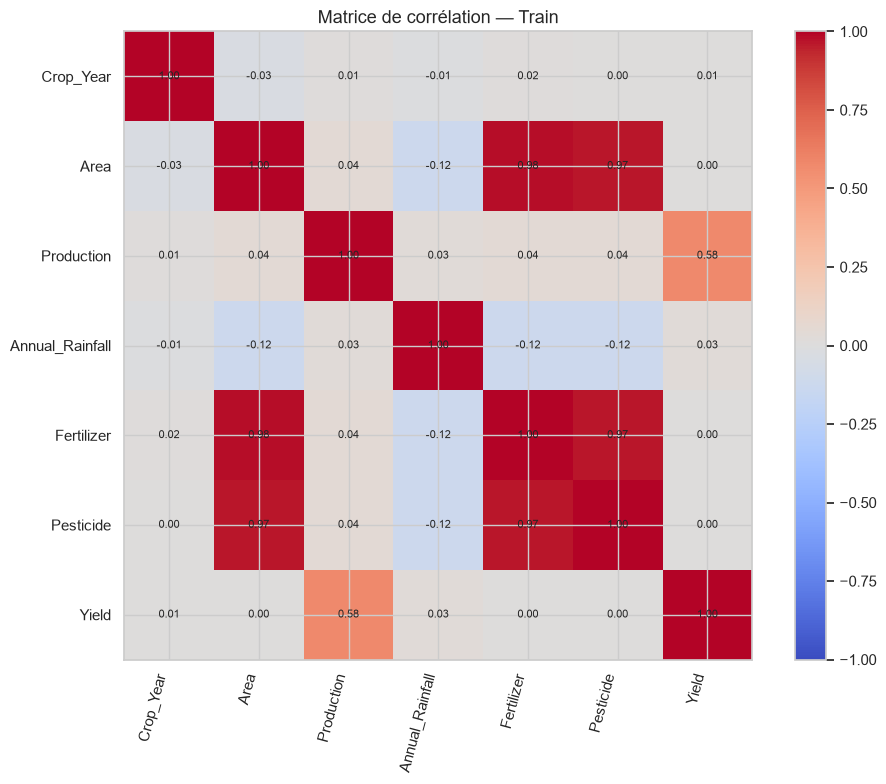


ANALYSE EXPLORATOIRE TERMINÉE

Nombre d'observations : 11813
Nombre de variables : 10

VALEURS MANQUANTES :


,manquants,pourcentage
Crop,0,0.0
Season,0,0.0
State,0,0.0
Crop_Year,0,0.0
Area,0,0.0
Production,0,0.0
Annual_Rainfall,0,0.0
Fertilizer,0,0.0
Pesticide,0,0.0
Yield,0,0.0



STATISTIQUES DESCRIPTIVES :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Crop,11813,55,Rice,695,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Season,11813,6,Kharif,4886,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,11813,30,Karnataka,885,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop_Year,11813.0,NaN,NaN,NaN,2009.089224,6.503873,1997.0,2004.0,2009.0,2015.0,2020.0
Area,11813.0,NaN,NaN,NaN,180971.151881,653585.88375,1.0,1387.0,9273.0,73907.0,9884913.0
Production,11813.0,NaN,NaN,NaN,14942922.029628,254182644.230955,0.0,1400.0,13300.0,120845.0,6326000000.0
Annual_Rainfall,11813.0,NaN,NaN,NaN,1430.027471,815.64892,301.3,933.2,1238.5,1635.9,6552.7
Fertilizer,11813.0,NaN,NaN,NaN,24294058.508348,89932847.73404,94.67,187239.36,1230996.69,9787990.32,1692266087.0
Pesticide,11813.0,NaN,NaN,NaN,48886.815206,183809.411383,0.09,356.65,2420.4,19492.902,3645426.48
Yield,11813.0,NaN,NaN,NaN,71.816973,827.301579,0.0,0.598,1.03,2.395556,16254.0



CORRÉLATIONS :


,Crop_Year,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
Crop_Year,1.000000,-0.034714,0.011894,-0.013534,0.015568,0.000672,0.007349
Area,-0.034714,1.000000,0.039489,-0.124294,0.978770,0.968271,0.002243
Production,0.011894,0.039489,1.000000,0.029180,0.041689,0.039456,0.575748
Annual_Rainfall,-0.013534,-0.124294,0.029180,1.000000,-0.119452,-0.117989,0.026699
Fertilizer,0.015568,0.978770,0.041689,-0.119452,1.000000,0.965503,0.003940
Pesticide,0.000672,0.968271,0.039456,-0.117989,0.965503,1.000000,0.002622
Yield,0.007349,0.002243,0.575748,0.026699,0.003940,0.002622,1.000000



FICHIERS GÉNÉRÉS :
Rapport Excel : C:\Users\Hp\Desktop\Projet_MLOps_Churn\reports\exploration_train\rapport_eda.xlsx
Matrice de corrélation : C:\Users\Hp\Desktop\Projet_MLOps_Churn\reports\exploration_train\correlations.png

Aucune donnée Train, Validation ou Test n'a été modifiée.


In [27]:

# ============================================================
# ANALYSE EXPLORATOIRE (EDA) SUR TRAIN
# Rapport Excel + Matrice de corrélation
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. CHEMINS ET DOSSIERS
# ------------------------------------------------------------

ROOT = Path(r"C:\Users\Hp\Desktop\Projet_MLOps_Churn")

eda_dir = ROOT / 'reports' / 'exploration_train'
eda_dir.mkdir(parents=True, exist_ok=True)

# Variables du projet
NUMERIC = [
    'Crop_Year',
    'Area',
    'Production',
    'Annual_Rainfall',
    'Fertilizer',
    'Pesticide'
]

CATEGORICAL = [
    'Crop',
    'Season',
    'State'
]

TARGET = 'Yield'

# Charger Train uniquement s'il n'est pas déjà en mémoire
if 'train' not in globals():
    train = pd.read_csv(ROOT / 'data' / 'train.csv')

print("Dimensions de Train :", train.shape)

# ------------------------------------------------------------
# 2. ANALYSE EXPLORATOIRE SUR TRAIN
# ------------------------------------------------------------

# Corrélations entre variables numériques et cible
correlations = train[
    NUMERIC + [TARGET]
].corr(numeric_only=True)

# Nombre de valeurs manquantes par variable
missing_report = (
    train.isna()
    .sum()
    .rename('manquants')
    .to_frame()
)

# Pourcentage de valeurs manquantes
missing_report['pourcentage'] = (
    train.isna().mean() * 100
).round(2)

# Statistiques descriptives
description = train.describe(include='all').T

# ------------------------------------------------------------
# 3. GÉNÉRATION DU RAPPORT EXCEL EDA
# ------------------------------------------------------------

rapport_excel = eda_dir / 'rapport_eda.xlsx'

with pd.ExcelWriter(
    rapport_excel,
    engine='openpyxl'
) as writer:

    # Statistiques descriptives
    description.to_excel(
        writer,
        sheet_name='description'
    )

    # Valeurs manquantes
    missing_report.to_excel(
        writer,
        sheet_name='manquants'
    )

    # Corrélations
    correlations.to_excel(
        writer,
        sheet_name='correlations'
    )

    # Distribution des variables catégorielles
    for col in CATEGORICAL:

        distribution = (
            train[col]
            .value_counts(dropna=False)
            .rename('effectif')
            .to_frame()
        )

        distribution.to_excel(
            writer,
            sheet_name=col[:31]
        )

# ------------------------------------------------------------
# 4. MATRICE DE CORRÉLATION
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    correlations,
    vmin=-1,
    vmax=1,
    cmap='coolwarm'
)

ax.set_xticks(range(len(correlations.columns)))
ax.set_yticks(range(len(correlations.index)))

ax.set_xticklabels(
    correlations.columns,
    rotation=75,
    ha='right'
)

ax.set_yticklabels(correlations.index)

# Afficher les coefficients dans les cellules
for i in range(len(correlations.index)):
    for j in range(len(correlations.columns)):

        valeur = correlations.iloc[i, j]

        if pd.notna(valeur):
            ax.text(
                j, i,
                f'{valeur:.2f}',
                ha='center',
                va='center',
                fontsize=8
            )

ax.set_title(
    'Matrice de corrélation — Train',
    fontsize=13
)

fig.colorbar(im, ax=ax)
fig.tight_layout()

chemin_correlation = eda_dir / 'correlations.png'

fig.savefig(
    chemin_correlation,
    dpi=140,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. AFFICHAGE DES RÉSULTATS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ANALYSE EXPLORATOIRE TERMINÉE")
print("=" * 65)

print("\nNombre d'observations :", train.shape[0])
print("Nombre de variables :", train.shape[1])

print("\nVALEURS MANQUANTES :")
display(missing_report)

print("\nSTATISTIQUES DESCRIPTIVES :")
display(description)

print("\nCORRÉLATIONS :")
display(correlations)

print("\nFICHIERS GÉNÉRÉS :")
print("Rapport Excel :", rapport_excel)
print("Matrice de corrélation :", chemin_correlation)

print("\nAucune donnée Train, Validation ou Test n'a été modifiée.")


## Étape 6 — Prétraitement et sauvegarde des transformations

**Rôle :** 
Créer automatiquement src/preprocessing.py.

Créer automatiquement src/preprocessing_production.py.

Apprendre les transformations uniquement sur Train.

Appliquer les transformations à Validation, Test et Simulation, sans les réapprendre.

Sauvegarder le prétraitement appris dans models/preprocessing.pkl.

Afficher à la fin les transformations effectuées, les dimensions des données et les chemins des fichiers générés.

In [31]:

from IPython.display import HTML, display

html = """
<style>
.pipeline {
    font-family: 'Segoe UI', Arial, sans-serif;
    max-width: 950px;
    margin: 20px auto;
    padding: 25px;
    background: #f5f7fb;
    border-radius: 18px;
    text-align: center;
    color: #17233c;
}

.pipeline * {
    box-sizing: border-box;
}

.pipeline h2 {
    margin-bottom: 8px;
    color: #17233c;
}

.pipeline .subtitle {
    color: #64748b;
    margin-bottom: 30px;
}

.pipeline .dataset {
    background: #182b50;
    color: white;
    padding: 20px;
    border-radius: 12px;
    font-size: 19px;
    font-weight: bold;
}

.pipeline .arrow {
    font-size: 30px;
    color: #64748b;
    margin: 12px 0;
}

.pipeline .branches {
    display: grid;
    grid-template-columns: 1fr 1fr;
    gap: 25px;
}

.pipeline .branch {
    border-radius: 14px;
    padding: 22px;
    border: 2px solid;
}

.pipeline .numeric {
    background: #eaf2ff;
    border-color: #8db5f5;
}

.pipeline .categorical {
    background: #f1eaff;
    border-color: #c4a5f5;
}

.pipeline .branch-title {
    font-size: 19px;
    font-weight: bold;
    margin-bottom: 12px;
}

.pipeline .numeric .branch-title {
    color: #2455ad;
}

.pipeline .categorical .branch-title {
    color: #7143b6;
}

.pipeline .variables {
    font-size: 13px;
    color: #64748b;
    min-height: 60px;
    line-height: 1.7;
}

.pipeline .step {
    background: white;
    border: 1px solid #dce3ee;
    padding: 17px 12px;
    border-radius: 10px;
    font-size: 16px;
    font-weight: 600;
}

.pipeline .step small {
    display: block;
    font-size: 12px;
    font-weight: normal;
    color: #64748b;
    margin-top: 6px;
}

.pipeline .merge {
    background: #e8f7ef;
    border: 2px solid #80b8a2;
    border-radius: 12px;
    padding: 20px;
}

.pipeline .merge-title {
    color: #16764d;
    font-size: 20px;
    font-weight: bold;
}

.pipeline .merge p {
    color: #475569;
    font-size: 14px;
}

.pipeline .output {
    background: #16764d;
    color: white;
    padding: 20px;
    border-radius: 12px;
    font-size: 19px;
    font-weight: bold;
}

.pipeline .footer {
    margin-top: 25px;
    color: #64748b;
    font-size: 13px;
    line-height: 1.8;
}

@media (max-width: 650px) {
    .pipeline .branches {
        grid-template-columns: 1fr;
    }
}
</style>

<div class="pipeline">

    <h2>Pipeline de prétraitement des données</h2>

    <p class="subtitle">
        Préparation des données pour la prédiction
        du rendement agricole
    </p>

    <div class="dataset">
        Dataset Train — 9 variables explicatives
    </div>

    <div class="arrow">↓</div>

    <div class="branches">

        <!-- VARIABLES NUMERIQUES -->
        <div class="branch numeric">

            <div class="branch-title">
                6 variables numériques
            </div>

            <div class="variables">
                Crop_Year · Area · Production<br>
                Annual_Rainfall · Fertilizer · Pesticide
            </div>

            <div class="step">
                1. Imputation médiane
                <small>Remplacement des valeurs manquantes</small>
            </div>

            <div class="arrow">↓</div>

            <div class="step">
                2. Transformation Yeo-Johnson
                <small>Réduction de l'asymétrie</small>
            </div>

            <div class="arrow">↓</div>

            <div class="step">
                3. Standardisation
                <small>Centrage et mise à l'échelle</small>
            </div>

        </div>

        <!-- VARIABLES CATEGORIELLES -->
        <div class="branch categorical">

            <div class="branch-title">
                3 variables catégorielles
            </div>

            <div class="variables">
                Crop · Season · State
            </div>

            <div class="step">
                1. Imputation par mode
                <small>Remplacement par la catégorie la plus fréquente</small>
            </div>

            <div class="arrow">↓</div>

            <div class="step">
                2. One-Hot Encoding
                <small>Conversion en colonnes binaires 0 / 1</small>
            </div>

        </div>

    </div>

    <div class="arrow">↓</div>

    <div class="merge">
        <div class="merge-title">
            ColumnTransformer
        </div>

        <p>
            Regroupe les variables numériques et catégorielles
            transformées en une matrice numérique.
        </p>
    </div>

    <div class="arrow">↓</div>

    <div class="output">
        Données prêtes pour le modèle ML
    </div>

    <div class="footer">
        Paramètres appris uniquement sur Train :
        <b>fit_transform()</b><br>

        Validation, Test, Simulation et Production :
        <b>transform()</b>
    </div>

</div>
"""

display(HTML(html))


In [28]:

# ============================================================
# PREPROCESSING — ENTRAINEMENT ET PRODUCTION
# ============================================================

import sys
import joblib
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 1. CONFIGURATION DES DOSSIERS
# ------------------------------------------------------------

ROOT = Path(r"C:\Users\Hp\Desktop\Projet_MLOps_Churn")

SRC = ROOT / "src"
MODELS = ROOT / "models"

SRC.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# Variables explicatives et cible
NUMERIC = [
    'Crop_Year', 'Area', 'Production',
    'Annual_Rainfall', 'Fertilizer', 'Pesticide'
]

CATEGORICAL = ['Crop', 'Season', 'State']
FEATURES = CATEGORICAL + NUMERIC
TARGET = 'Yield'

# ------------------------------------------------------------
# 2. CREATION DE preprocessing.py
# ------------------------------------------------------------

code_preprocessing = '''
import joblib

from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, PowerTransformer

from nettoyage_dataset import NUMERIC, CATEGORICAL, FEATURES


def creer_preprocessing():

    # Transformations numériques
    numerique = Pipeline([
        (
            "imputation",
            SimpleImputer(
                strategy="median",
                keep_empty_features=True
            )
        ),
        (
            "puissance",
            PowerTransformer(
                method="yeo-johnson",
                standardize=True
            )
        )
    ])

    # Transformations catégorielles
    categoriel = Pipeline([
        (
            "imputation",
            SimpleImputer(
                strategy="most_frequent",
                keep_empty_features=True
            )
        ),
        (
            "encodage",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ])

    return ColumnTransformer(
        transformers=[
            ("numerique", numerique, NUMERIC),
            ("categoriel", categoriel, CATEGORICAL)
        ],
        remainder="drop"
    )


def entrainer_preprocessing(
    train,
    validation,
    test,
    simulation,
    chemin_pkl
):

    # Nouveau preprocessing non entraîné
    preprocessor = creer_preprocessing()

    # Apprentissage uniquement sur Train
    X_train = preprocessor.fit_transform(
        train[FEATURES]
    )

    # Application aux autres ensembles
    X_validation = preprocessor.transform(
        validation[FEATURES]
    )

    X_test = preprocessor.transform(
        test[FEATURES]
    )

    X_simulation = preprocessor.transform(
        simulation[FEATURES]
    )

    # Vérifier la cohérence des dimensions
    assert (
        X_train.shape[1]
        == X_validation.shape[1]
        == X_test.shape[1]
        == X_simulation.shape[1]
    )

    # Sauvegarder le preprocessing appris
    chemin_pkl = Path(chemin_pkl)
    chemin_pkl.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    joblib.dump(preprocessor, chemin_pkl)

    return (
        preprocessor,
        X_train,
        X_validation,
        X_test,
        X_simulation
    )
'''

chemin_preprocessing = SRC / "preprocessing.py"

chemin_preprocessing.write_text(
    code_preprocessing.strip() + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 3. CREATION DE preprocessing_production.py
# ------------------------------------------------------------

code_production = '''
import joblib

from pathlib import Path
from nettoyage_production import nettoyer_production


def transformer_production(df, chemin_pkl):

    # 1. Valider et nettoyer les nouvelles données
    donnees_valides, avertissements = (
        nettoyer_production(df)
    )

    # 2. Charger le preprocessing appris sur Train
    preprocessor = joblib.load(Path(chemin_pkl))

    # 3. Vérifier s'il existe des observations valides
    if donnees_valides.empty:
        return None, avertissements

    # 4. Appliquer les transformations sans réapprentissage
    X_production = preprocessor.transform(
        donnees_valides
    )

    return X_production, avertissements
'''

chemin_production = SRC / "preprocessing_production.py"

chemin_production.write_text(
    code_production.strip() + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 4. CHARGEMENT DES ENSEMBLES
# ------------------------------------------------------------

# Utiliser les ensembles existants en mémoire,
# sinon les charger depuis data/

for nom in ["train", "validation", "test", "simulation"]:

    if nom not in globals():
        chemin = ROOT / "data" / f"{nom}.csv"

        if not chemin.exists():
            raise FileNotFoundError(
                f"Fichier introuvable : {chemin}"
            )

        globals()[nom] = pd.read_csv(chemin)

# ------------------------------------------------------------
# 5. APPRENTISSAGE ET APPLICATION DES TRANSFORMATIONS
# ------------------------------------------------------------

# Charger la version actuelle du script
import importlib
import preprocessing

importlib.invalidate_caches()
importlib.reload(preprocessing)

chemin_pkl = MODELS / "preprocessing.pkl"

(
    preprocessor,
    X_train,
    X_validation,
    X_test,
    X_simulation
) = preprocessing.entrainer_preprocessing(
    train=train,
    validation=validation,
    test=test,
    simulation=simulation,
    chemin_pkl=chemin_pkl
)

# Cibles non transformées
y_train = train[TARGET]
y_validation = validation[TARGET]
y_test = test[TARGET]
y_simulation = simulation[TARGET]

# ------------------------------------------------------------
# 6. INFORMATIONS SUR LES TRANSFORMATIONS APPPRISES
# ------------------------------------------------------------

pipeline_num = (
    preprocessor.named_transformers_["numerique"]
)

pipeline_cat = (
    preprocessor.named_transformers_["categoriel"]
)

imputer_num = pipeline_num.named_steps["imputation"]
imputer_cat = pipeline_cat.named_steps["imputation"]
encodeur = pipeline_cat.named_steps["encodage"]

# ------------------------------------------------------------
# 7. RAPPORT FINAL
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PREPROCESSING TERMINE")
print("=" * 65)

print("\n1. TRANSFORMATIONS NUMERIQUES")
print("   - Imputation par médiane")
print("   - Transformation Yeo-Johnson")
print("   - Standardisation")

print("\nMédianes apprises sur Train :")
for colonne, mediane in zip(
    NUMERIC,
    imputer_num.statistics_
):
    print(f"   {colonne} : {mediane}")

print("\n2. TRANSFORMATIONS CATEGORIELLES")
print("   - Imputation par valeur la plus fréquente")
print("   - Encodage One-Hot")

print("\nCatégories apprises sur Train :")
for colonne, categories in zip(
    CATEGORICAL,
    encodeur.categories_
):
    print(f"   {colonne} : {len(categories)} catégories")

print("\n3. DIMENSIONS APRES TRANSFORMATION")

print("   Train      :", X_train.shape)
print("   Validation :", X_validation.shape)
print("   Test       :", X_test.shape)
print("   Simulation :", X_simulation.shape)

print("\n4. FICHIERS GENERES")

print("   preprocessing.py :")
print("  ", chemin_preprocessing)

print("   preprocessing_production.py :")
print("  ", chemin_production)

print("   preprocessing.pkl :")
print("  ", chemin_pkl)

print("\n5. VERIFICATION")
print("   Transformations apprises uniquement sur Train.")
print("   Validation, Test et Simulation : transform uniquement.")
print("   Aucun fichier de données source n'a été modifié.")

print("\nPREPROCESSING SAUVEGARDE AVEC SUCCES.")



PREPROCESSING TERMINE

1. TRANSFORMATIONS NUMERIQUES
   - Imputation par médiane
   - Transformation Yeo-Johnson
   - Standardisation

Médianes apprises sur Train :
   Crop_Year : 2009.0
   Area : 9273.0
   Production : 13300.0
   Annual_Rainfall : 1238.5
   Fertilizer : 1230996.69
   Pesticide : 2420.4

2. TRANSFORMATIONS CATEGORIELLES
   - Imputation par valeur la plus fréquente
   - Encodage One-Hot

Catégories apprises sur Train :
   Crop : 55 catégories
   Season : 6 catégories
   State : 30 catégories

3. DIMENSIONS APRES TRANSFORMATION
   Train      : (11813, 97)
   Validation : (1969, 97)
   Test       : (1969, 97)
   Simulation : (3938, 97)

4. FICHIERS GENERES
   preprocessing.py :
   C:\Users\Hp\Desktop\Projet_MLOps_Churn\src\preprocessing.py
   preprocessing_production.py :
   C:\Users\Hp\Desktop\Projet_MLOps_Churn\src\preprocessing_production.py
   preprocessing.pkl :
   C:\Users\Hp\Desktop\Projet_MLOps_Churn\models\preprocessing.pkl

5. VERIFICATION
   Transformations ap

## Étape 7 — Entraînement du modèle V1 avec Gradient Boosting

Rôle : entraîner un modèle de régression GradientBoostingRegressor pour prédire le rendement agricole (Yield), exclusivement à partir des données Train.


Dans cette cellule, nous allons :
1. Charger les données Train et le prétraitement déjà appris à l'étape précédente (preprocessing.pkl).
2. Appliquer les transformations à Train sans les réapprendre.
3. Entraîner le modèle Gradient Boosting avec random_state=42 pour assurer la reproductibilité.
4. Sauvegarder le modèle dans models/model_v1.pkl.
5. Enregistrer sa configuration et l'empreinte SHA-256 des données Train pour assurer la traçabilité.
Important : contrairement à ton ancien code, nous n'allons pas réentraîner le preprocessing, puisqu'il a déjà été appris et sauvegardé à l'étape précédente

In [32]:

# ============================================================
# ETAPE 7 — ENTRAINEMENT DU MODELE V1 : GRADIENT BOOSTING
# ============================================================

import sys
import json
import joblib
import hashlib
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

ROOT = Path(r"C:\Users\Hp\Desktop\Projet_MLOps_Churn")

SRC = ROOT / "src"
MODELS = ROOT / "models"
REFERENCES = ROOT / "references"

SRC.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)
REFERENCES.mkdir(parents=True, exist_ok=True)

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# ------------------------------------------------------------
# 2. CREATION DU SCRIPT train.py
# ------------------------------------------------------------

code_train = '''
import json
import joblib
import hashlib
import pandas as pd

from pathlib import Path
from sklearn.ensemble import GradientBoostingRegressor
from nettoyage_dataset import FEATURES, TARGET


def entrainer(root):

    root = Path(root)

    # Charger les données Train
    data_path = root / "data" / "train.csv"
    train = pd.read_csv(data_path)

    # Charger le preprocessing déjà entraîné
    preprocessing_path = root / "models" / "preprocessing.pkl"

    preprocessor = joblib.load(preprocessing_path)

    # Appliquer les transformations sans réapprentissage
    X_train = preprocessor.transform(train[FEATURES])
    y_train = train[TARGET]

    # Création du modèle Gradient Boosting
    model = GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )

    # Entraînement exclusivement sur Train
    model.fit(X_train, y_train)

    # Sauvegarde du modèle
    model_path = root / "models" / "model_v1.pkl"
    joblib.dump(model, model_path)

    # Configuration et traçabilité
    config = {
        "version": "V1",
        "type": "regression",
        "algorithme": "GradientBoostingRegressor",
        "parametres": {
            "n_estimators": 100,
            "learning_rate": 0.1,
            "max_depth": 3,
            "random_state": 42
        },
        "cible": TARGET,
        "features": FEATURES,
        "train_sha256": hashlib.sha256(
            data_path.read_bytes()
        ).hexdigest(),
        "preprocessing": "preprocessing.pkl",
        "modele": "model_v1.pkl"
    }

    config_path = (
        root / "references" / "config_model_v1.json"
    )

    config_path.write_text(
        json.dumps(
            config,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    return model, preprocessor
'''

chemin_train = SRC / "train.py"

chemin_train.write_text(
    code_train.strip() + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 3. ENTRAINEMENT DU MODELE
# ------------------------------------------------------------

import importlib
import train as module_train

importlib.invalidate_caches()
importlib.reload(module_train)

model, preprocessor = module_train.entrainer(ROOT)

# ------------------------------------------------------------
# 4. CONFIRMATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ENTRAINEMENT DU MODELE V1 TERMINE")
print("=" * 65)

print("\nAlgorithme : GradientBoostingRegressor")
print("Type : Régression")
print("Cible : Yield")

print("\nParamètres :")
print("  n_estimators : 100")
print("  learning_rate : 0.1")
print("  max_depth : 3")
print("  random_state : 42")

print("\nFICHIERS :")

print("Script d'entraînement :")
print(ROOT / "src" / "train.py")

print("\nModèle entraîné :")
print(ROOT / "models" / "model_v1.pkl")

print("\nConfiguration :")
print(ROOT / "references" / "config_model_v1.json")

print("\nPreprocessing réutilisé :")
print(ROOT / "models" / "preprocessing.pkl")

print("\nAucune donnée Validation, Test ou Simulation utilisée.")
print("Le preprocessing n'a pas été réentraîné.")



ENTRAINEMENT DU MODELE V1 TERMINE

Algorithme : GradientBoostingRegressor
Type : Régression
Cible : Yield

Paramètres :
  n_estimators : 100
  learning_rate : 0.1
  max_depth : 3
  random_state : 42

FICHIERS :
Script d'entraînement :
C:\Users\Hp\Desktop\Projet_MLOps_Churn\src\train.py

Modèle entraîné :
C:\Users\Hp\Desktop\Projet_MLOps_Churn\models\model_v1.pkl

Configuration :
C:\Users\Hp\Desktop\Projet_MLOps_Churn\references\config_model_v1.json

Preprocessing réutilisé :
C:\Users\Hp\Desktop\Projet_MLOps_Churn\models\preprocessing.pkl

Aucune donnée Validation, Test ou Simulation utilisée.
Le preprocessing n'a pas été réentraîné.



## Étape 8 — Validation du modèle V1 : Gradient Boosting

### 1. Rôle de cette étape

L'objectif de cette étape est d'évaluer les performances du modèle
Gradient Boosting V1, entraîné précédemment sur Train, en utilisant
exclusivement les données de Validation.

Cette étape permet de vérifier la capacité du modèle à généraliser
sur des données qu'il n'a jamais utilisées pendant son entraînement.

Pour cela, nous allons :

1. Charger les données de Validation.
2. Charger le preprocessing et le modèle V1 déjà entraînés.
3. Appliquer le preprocessing aux données de Validation sans
   réapprendre ses paramètres.
4. Prédire les valeurs de Yield.
5. Comparer les valeurs prédites aux valeurs réelles.
6. Calculer les métriques R², MAE et RMSE.
7. Enregistrer les résultats de validation.

**Remarque :** aucun réentraînement du modèle ou du preprocessing
n'est effectué dans cette étape. Les données Test et Simulation
ne sont pas utilisées.

### 2. Métriques utilisées et pourquoi

Puisque notre variable cible `Yield` est continue, nous sommes
dans un problème de régression. Nous utilisons trois métriques :

**R² — Coefficient de détermination**

- Mesure la proportion de variance de Yield expliquée par le modèle.
- Permet d'évaluer la capacité globale du modèle à expliquer
  les variations de la cible.
- Interprétation :
  - R² = 1 : prédictions parfaites.
  - R² proche de 1 : très bonne capacité explicative.
  - R² = 0 : performance équivalente à une prédiction constante
    égale à la moyenne des valeurs réelles de Validation.
  - R² < 0 : performance inférieure à cette référence.

**MAE — Mean Absolute Error**

- Mesure la moyenne des écarts absolus entre les valeurs réelles
  et les valeurs prédites.
- Permet de connaître l'erreur moyenne de prédiction,
  exprimée dans la même unité que Yield.
- Interprétation :
  - MAE = 0 : aucune erreur.
  - Plus la MAE est faible, plus les prédictions sont précises.
  - Exemple : MAE = 50 signifie que les prédictions s'écartent
    en moyenne de 50 unités des valeurs réelles.

**RMSE — Root Mean Squared Error**

- Mesure l'erreur quadratique moyenne, après application
  de la racine carrée.
- Pénalise davantage les grandes erreurs de prédiction.
- Permet de détecter si le modèle commet des erreurs importantes.
- Interprétation :
  - RMSE = 0 : aucune erreur.
  - Plus la RMSE est faible, meilleur est le résultat.
  - Une RMSE nettement supérieure à la MAE peut indiquer
    la présence de grandes erreurs sur certaines observations.

### 3. Comment interpréter les résultats ?

Un modèle est généralement considéré comme performant lorsque :

- Son R² est élevé, idéalement proche de 1.
- Sa MAE est faible par rapport à l'échelle de Yield.
- Sa RMSE est faible et ne révèle pas d'erreurs excessives.

Les valeurs acceptables dépendent des besoins métier et
de la distribution réelle de Yield.

Les résultats obtenus sur Validation permettent de décider
si le modèle V1 peut être conservé ou s'il faut optimiser
ses hyperparamètres.

**Important :** Validation sert à sélectionner et ajuster
le modèle. Test sera réservé à son évaluation finale.

### 4. Fichiers générés

- `src/metriques.py` : calcul des métriques de régression.
- `src/validation.py` : script de validation du modèle V1.
- `references/validation_v1.json` : résultats de validation.


In [33]:

# ============================================================
# ETAPE 8 — VALIDATION DU MODELE V1 : GRADIENT BOOSTING
# ============================================================

import sys
import json
import importlib
from pathlib import Path

# ------------------------------------------------------------
# 1. CONFIGURATION DES CHEMINS
# ------------------------------------------------------------

ROOT = Path(r"C:\Users\Hp\Desktop\Projet_MLOps_Churn")

SRC = ROOT / "src"
REFERENCES = ROOT / "references"

SRC.mkdir(parents=True, exist_ok=True)
REFERENCES.mkdir(parents=True, exist_ok=True)

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# ------------------------------------------------------------
# 2. CREATION DU SCRIPT metriques.py
# ------------------------------------------------------------

code_metriques = '''
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


def metriques_regression(y_true, y_pred):

    return {
        "n": int(len(y_true)),
        "r2": float(r2_score(y_true, y_pred)),
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(
            np.sqrt(mean_squared_error(y_true, y_pred))
        )
    }
'''

(SRC / "metriques.py").write_text(
    code_metriques.strip() + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 3. CREATION DU SCRIPT validation.py
# ------------------------------------------------------------

code_validation = '''
import json
import joblib
import pandas as pd

from pathlib import Path

from nettoyage_dataset import FEATURES, TARGET
from metriques import metriques_regression


def valider(root):

    root = Path(root)

    # Charger les données Validation
    validation = pd.read_csv(
        root / "data" / "validation.csv"
    )

    # Charger le preprocessing et le modèle V1
    preprocessor = joblib.load(
        root / "models" / "preprocessing.pkl"
    )

    model = joblib.load(
        root / "models" / "model_v1.pkl"
    )

    # Transformer Validation sans réentraînement
    X_validation = preprocessor.transform(
        validation[FEATURES]
    )

    y_validation = validation[TARGET]

    # Prédire Yield
    predictions = model.predict(X_validation)

    # Calculer les métriques
    scores = metriques_regression(
        y_validation,
        predictions
    )

    # Préparer le rapport
    resultat = {
        "modele": "model_v1.pkl",
        "algorithme": "GradientBoostingRegressor",
        "ensemble": "validation",
        "metriques": scores,
        "seuil_classification": None,
        "note": "Régression : aucun seuil de classification"
    }

    # Enregistrer le rapport JSON
    chemin_rapport = (
        root / "references" / "validation_v1.json"
    )

    chemin_rapport.write_text(
        json.dumps(
            resultat,
            indent=4,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    return resultat
'''

(SRC / "validation.py").write_text(
    code_validation.strip() + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 4. EXECUTION DE LA VALIDATION
# ------------------------------------------------------------

import metriques
import validation

importlib.invalidate_caches()
importlib.reload(metriques)
importlib.reload(validation)

resultat_validation = validation.valider(ROOT)

# ------------------------------------------------------------
# 5. AFFICHAGE DES RESULTATS
# ------------------------------------------------------------

scores = resultat_validation["metriques"]

print("=" * 60)
print("VALIDATION DU MODELE V1 — GRADIENT BOOSTING")
print("=" * 60)

print(f"\nNombre d'observations : {scores['n']}")

print("\nMETRIQUES DE VALIDATION")

print(f"R²   : {scores['r2']:.4f}")
print(f"R² % : {scores['r2'] * 100:.2f} %")
print(f"MAE  : {scores['mae']:.4f}")
print(f"RMSE : {scores['rmse']:.4f}")

print("\nINTERPRETATION")

print(
    f"Le modèle explique {scores['r2'] * 100:.2f} % "
    "de la variance de Yield sur Validation."
)

print(
    f"L'écart absolu moyen entre les valeurs "
    f"réelles et prédites est de {scores['mae']:.2f} "
    "unités de Yield."
)

print(
    f"La RMSE est de {scores['rmse']:.2f} "
    "unités de Yield."
)

if scores["rmse"] > scores["mae"] * 1.5:
    print(
        "La RMSE est sensiblement supérieure à la MAE : "
        "certaines erreurs peuvent être importantes."
    )

print("\nFICHIERS GENERES")

print(ROOT / "src" / "metriques.py")
print(ROOT / "src" / "validation.py")
print(ROOT / "references" / "validation_v1.json")

print("\nAucun réentraînement effectué.")
print("Aucune utilisation des données Test ou Simulation.")


VALIDATION DU MODELE V1 — GRADIENT BOOSTING

Nombre d'observations : 1969

METRIQUES DE VALIDATION
R²   : 0.9566
R² % : 95.66 %
MAE  : 14.0418
RMSE : 195.5271

INTERPRETATION
Le modèle explique 95.66 % de la variance de Yield sur Validation.
L'écart absolu moyen entre les valeurs réelles et prédites est de 14.04 unités de Yield.
La RMSE est de 195.53 unités de Yield.
La RMSE est sensiblement supérieure à la MAE : certaines erreurs peuvent être importantes.

FICHIERS GENERES
C:\Users\Hp\Desktop\Projet_MLOps_Churn\src\metriques.py
C:\Users\Hp\Desktop\Projet_MLOps_Churn\src\validation.py
C:\Users\Hp\Desktop\Projet_MLOps_Churn\references\validation_v1.json

Aucun réentraînement effectué.
Aucune utilisation des données Test ou Simulation.


In [36]:

# ============================================================
# ETAPE 8 — CREATION DES SCRIPTS DE VALIDATION REUTILISABLES
# ============================================================

import sys
import json
import importlib
from pathlib import Path

# ------------------------------------------------------------
# 1. CONFIGURATION DES CHEMINS
# ------------------------------------------------------------

ROOT = Path(r"C:\Users\Hp\Desktop\Projet_MLOps_Churn")

SRC = ROOT / "src"
REFERENCES = ROOT / "references"

SRC.mkdir(parents=True, exist_ok=True)
REFERENCES.mkdir(parents=True, exist_ok=True)

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# ------------------------------------------------------------
# 2. CREATION DU SCRIPT metriques.py
# ------------------------------------------------------------

code_metriques = '''
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


def metriques_regression(y_true, y_pred):

    return {
        "n": int(len(y_true)),
        "r2": float(r2_score(y_true, y_pred)),
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(
            np.sqrt(mean_squared_error(y_true, y_pred))
        )
    }
'''

(SRC / "metriques.py").write_text(
    code_metriques.strip() + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 3. CREATION DU SCRIPT validation.py
# ------------------------------------------------------------

code_validation = '''
import json
import joblib
import pandas as pd

from pathlib import Path

from nettoyage_dataset import FEATURES, TARGET
from metriques import metriques_regression


def valider(
    root,
    version="v1",
    nom_modele=None,
    nom_preprocessing=None
):

    root = Path(root)

    # 1. Définir les fichiers de la version demandée
    if nom_modele is None:
        nom_modele = f"model_{version}.pkl"

    if nom_preprocessing is None:
        if version == "v1":
            nom_preprocessing = "preprocessing.pkl"
        else:
            nom_preprocessing = f"preprocessing_{version}.pkl"

    chemin_modele = root / "models" / nom_modele
    chemin_preprocessing = root / "models" / nom_preprocessing

    # 2. Vérifier que les fichiers existent
    if not chemin_modele.exists():
        raise FileNotFoundError(
            f"Modèle introuvable : {chemin_modele}"
        )

    if not chemin_preprocessing.exists():
        raise FileNotFoundError(
            f"Preprocessing introuvable : {chemin_preprocessing}"
        )

    # 3. Charger Validation
    validation = pd.read_csv(
        root / "data" / "validation.csv"
    )

    # 4. Charger le preprocessing et le modèle
    preprocessor = joblib.load(chemin_preprocessing)
    model = joblib.load(chemin_modele)

    # 5. Transformer Validation sans fit
    X_validation = preprocessor.transform(
        validation[FEATURES]
    )

    y_validation = validation[TARGET]

    # 6. Prédire Yield
    predictions = model.predict(X_validation)

    # 7. Calculer les métriques
    scores = metriques_regression(
        y_validation,
        predictions
    )

    # 8. Préparer le rapport
    resultat = {
        "version": version,
        "modele": nom_modele,
        "preprocessing": nom_preprocessing,
        "algorithme": type(model).__name__,
        "ensemble": "validation",
        "metriques": scores,
        "note": "Régression : R2, MAE et RMSE"
    }

    # 9. Sauvegarder le rapport JSON
    chemin_rapport = (
        root / "references" / f"validation_{version}.json"
    )

    chemin_rapport.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    chemin_rapport.write_text(
        json.dumps(
            resultat,
            indent=4,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    return resultat
'''

(SRC / "validation.py").write_text(
    code_validation.strip() + "\n",
    encoding="utf-8"
)

print("SCRIPTS CREES AVEC SUCCES")
print(SRC / "metriques.py")
print(SRC / "validation.py")


SCRIPTS CREES AVEC SUCCES
C:\Users\Hp\Desktop\Projet_MLOps_Churn\src\metriques.py
C:\Users\Hp\Desktop\Projet_MLOps_Churn\src\validation.py


## Étape 9 — Test final et performances de référence

**Rôle :** évaluer **une seule fois** le modèle choisi sur Test, enregistrer les métriques de référence et produire les figures « réel vs prédit » et « distribution des résidus ». Pour la régression, il n'existe ni matrice de confusion ni effectifs de classes.

In [ ]:
(ROOT/'src/test.py').write_text("import json,joblib,pandas as pd,numpy as np\nimport matplotlib.pyplot as plt\nfrom pathlib import Path\nfrom nettoyage_dataset import FEATURES,TARGET\nfrom metriques import metriques_regression\n\ndef tester(root):\n    root=Path(root);d=pd.read_csv(root/'data/test.csv')\n    prep=joblib.load(root/'models/preprocessing.pkl');model=joblib.load(root/'models/model_v1.pkl')\n    pred=model.predict(prep.transform(d[FEATURES]))\n    result={'modele':'model_v1.pkl','preprocessing':'preprocessing.pkl','ensemble':'test','metriques':metriques_regression(d[TARGET],pred),\n            'statistiques_cible':{'n':len(d),'moyenne':float(d[TARGET].mean()),'ecart_type':float(d[TARGET].std())}}\n    (root/'references/performance_v1.json').write_text(json.dumps(result,indent=2,ensure_ascii=False),encoding='utf-8')\n    dossier=root/'reports/evaluation_v1';dossier.mkdir(parents=True,exist_ok=True)\n    pd.DataFrame({'reel':d[TARGET],'prediction':pred,'residu':d[TARGET]-pred}).to_csv(dossier/'predictions_test.csv',index=False)\n    fig,ax=plt.subplots(figsize=(6,6));ax.scatter(d[TARGET],pred,alpha=.3,s=10);ax.set(xlabel='Yield réel',ylabel='Yield prédit',title='Test : réel vs prédit');fig.tight_layout();fig.savefig(dossier/'reel_vs_predit.png',dpi=140);plt.close(fig)\n    fig,ax=plt.subplots(figsize=(8,4));ax.hist(d[TARGET]-pred,bins=30);ax.set(xlabel='Résidu',title='Distribution des résidus — Test');fig.tight_layout();fig.savefig(dossier/'residus.png',dpi=140);plt.close(fig)\n    return result\n",encoding='utf-8')
from test import tester
resultat_test=tester(ROOT)
print(json.dumps(resultat_test,indent=2,ensure_ascii=False))

## Contrôle final des livrables

Tous les fichiers ci-dessous sont créés **lorsque les cellules sont exécutées** avec le CSV agricole. Le notebook est fourni sans résultats fabriqués : les scores dépendent des données réellement chargées.

In [ ]:
livrables = ['src/nettoyage_dataset.py','src/nettoyage_production.py','data/dataset_clean.csv',
'data/train.csv','data/validation.csv','data/test.csv','data/simulation_T0.csv',
'src/calcul_statistiques.py','references/statistiques_train.json','references/train.csv',
'src/visualiser_distributions.py','notebooks/eda_train.ipynb','reports/exploration_train/rapport_eda.xlsx',
'references/scenario_drift.json','src/preprocessing.py','src/preprocessing_production.py','models/preprocessing.pkl',
'src/train.py','models/model_v1.pkl','references/config_model_v1.json',
'src/validation.py','references/validation_v1.json','src/test.py','references/performance_v1.json']
for p in livrables: print(('OK ' if (ROOT/p).exists() else 'MANQUANT ')+p)

---
# Annexe — Notebook Kaggle original conservé

Les cellules de **code** ci-dessous sont conservées **telles quelles** et dans leur ordre initial, à titre de référence. Les explications Markdown d'origine sont également conservées : certaines sont en anglais pour garantir une archive fidèle. Les étapes MLOps ci-dessus sont entièrement en français et indépendantes de cette annexe. Les sorties de l'original ont été supprimées pour alléger le fichier. **Ne pas exécuter cette annexe en séquence avec le pipeline MLOps**.

# Crop Yield Prediction using Machine Learning

### Importing Libraries

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

import warnings
import missingno
warnings.filterwarnings("ignore")
%matplotlib inline
sns.set(style="darkgrid",font_scale=1.5)
pd.set_option("display.max.columns",None)
pd.set_option("display.max.rows",None)

In this section, essential libraries and settings were imported and configured to facilitate data analysis, visualization, and statistical modeling for crop yield prediction. Here's a breakdown of the imports:

1. **Core Libraries:**
   - **`numpy` and `pandas`:** For numerical computations and data manipulation.
   - **`scipy.stats`:** To perform advanced statistical tests and analyses.

2. **Statistical Analysis Tools:**
   - **`variance_inflation_factor` from `statsmodels`:** Helps detect multicollinearity among features.

3. **Visualization Libraries:**
   - **`matplotlib` and `seaborn`:** For creating static visualizations with improved aesthetics.
   - **`plotly.express` and `plotly.graph_objects`:** To create interactive visualizations.
   - **`missingno`:** Specially used for visualizing missing data patterns.

4. **Miscellaneous Settings:**
   - **Warnings Filtering:** Suppressed warnings using `warnings.filterwarnings` to improve notebook readability.
   - **Seaborn Style:** Set to `darkgrid` for better visual appeal.
   - **Pandas Display Options:** Adjusted to show all rows and columns, ensuring comprehensive data visibility.
   - **Matplotlib Inline Backend:** Ensures plots are displayed inline within the notebook.

These libraries and configurations form the foundational toolkit for the analysis and modeling pipeline, enhancing both efficiency and presentation quality.

### Machine learning library and performance metrices

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.ensemble import VotingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import BaggingRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder 
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import PowerTransformer

This section introduces an expanded set of libraries, incorporating advanced machine learning models, preprocessing tools, and evaluation metrics. Below is a detailed breakdown:

---

#### **Machine Learning Models:**
- **Linear Models:**
  - **`LinearRegression`:** A foundational regression model for linear relationships.
  - **`Ridge`, `Lasso`, `ElasticNet`:** Linear models with different regularization techniques to prevent overfitting.

- **Tree-Based Models:**
  - **`DecisionTreeRegressor`:** A non-linear model that splits data recursively based on feature values.
  - **`RandomForestRegressor`:** An ensemble method combining multiple decision trees to enhance accuracy and reduce overfitting.

- **Boosting Algorithms:**
  - **`GradientBoostingRegressor`, `AdaBoostRegressor`:** Boosting methods that sequentially refine predictions to reduce error.
  - **`XGBRegressor`, `CatBoostRegressor`, `LGBMRegressor`:** Highly efficient gradient boosting libraries tailored for speed and accuracy.

- **Ensemble and Non-Parametric Models:**
  - **`VotingRegressor`:** Combines predictions from multiple models for a consensus output.
  - **`BaggingRegressor`:** Averages predictions from multiple base models trained on different data subsets.
  - **`KNeighborsRegressor`:** A non-parametric model that predicts based on the similarity to neighboring data points.

---

#### **Data Splitting and Optimization:**
- **`train_test_split`:** Ensures unbiased evaluation by dividing the data into training and testing subsets.
- **`GridSearchCV`:** Automates hyperparameter tuning by exhaustively searching the best parameter combinations.

---

#### **Performance Metrics:**
- **`r2_score`:** Evaluates the proportion of variance explained by the model (higher values indicate better fit).
- **`mean_squared_error`:** Measures the average squared difference between predicted and actual values.

---

#### **Preprocessing Tools:**
- **Scaling and Transformation:**
  - **`StandardScaler`:** Normalizes data by centering and scaling it.
  - **`MinMaxScaler`:** Scales data to a fixed range, typically [0, 1].
  - **`PowerTransformer`:** Applies transformations to stabilize variance and improve data distribution.

- **Encoding Categorical Data:**
  - **`LabelEncoder`:** Converts categorical labels into numerical values.
  - **`OneHotEncoder`:** Encodes categorical features into binary indicator variables.

---

This enriched set of models, tools, and techniques ensures flexibility and scalability in addressing the crop yield prediction problem, accommodating diverse data types and regression complexities.

### libraries version

In [ ]:
libraries = {
    "numpy": "np",
    "pandas": "pd",
    "scipy": "scipy",
    "statsmodels": "statsmodels",
    "matplotlib": "matplotlib",
    "seaborn": "sns",
    "plotly": "plotly",
    "scikit-learn": "sklearn",
    "xgboost": "xgboost",
    "catboost": "catboost",
    "lightgbm": "lightgbm"
}

# Dictionary to store library versions
library_versions = {}

# Check and print versions for each library
for lib in libraries.keys():
    try:
        # Special case for scikit-learn to debug the import explicitly
        if lib == "scikit-learn":
            import sklearn
            library_versions[lib] = sklearn.__version__
        else:
            module = __import__(lib)
            library_versions[lib] = module.__version__
    except ModuleNotFoundError:
        library_versions[lib] = "Not installed"
    except Exception as e:
        library_versions[lib] = f"Error: {str(e)}"

# Display results
for lib, version in library_versions.items():
    if version == "Not installed":
        print(f"{lib}: Not installed. Install using 'pip install {lib}'")
    else:
        print(f"{lib}: {version}")


This section is dedicated to verifying and recording the versions of the libraries used in the crop yield prediction model. This ensures compatibility and helps track the specific versions for reproducibility and troubleshooting. Below are the results of the version check for each library:

---

#### **Installed Libraries and Versions:**
1. **`numpy`**: 1.26.4
2. **`pandas`**: 2.2.2
3. **`scipy`**: 1.13.1
4. **`statsmodels`**: 0.14.2
5. **`matplotlib`**: 3.8.4
6. **`seaborn`**: 0.13.2
7. **`plotly`**: 5.22.0
8. **`scikit-learn`**: 1.4.2
9. **`xgboost`**: 2.1.1
10. **`catboost`**: 1.2.3
11. **`lightgbm`**: 4.5.0

---

#### **Purpose:**
This version check helps ensure that all required libraries are installed correctly and that their versions align with the project's requirements. It's a good practice to document library versions, as different versions might have varying features and behaviors that could impact model performance or reproducibility.

#### **Additional Notes:**
- If any library was not installed, the code provided an installation prompt (`pip install <library>`), ensuring that all dependencies are met.
- In case of errors during version retrieval, those errors were captured and reported, ensuring that potential issues could be easily identified and fixed.

This step is essential for maintaining a consistent environment across different stages of the analysis and for future reproducibility.

# Loading Dataset

In [ ]:
df = pd.read_csv("/kaggle/input/crop-yield-in-indian-states-dataset/crop_yield.csv")

In this step, the dataset was loaded using **`pandas.read_csv`** into a DataFrame. This function is commonly used to import tabular data from a CSV file for further analysis.

- **`pd.read_csv("crop_yield.csv")`:** Reads the dataset named `crop_yield.csv` and stores it in the DataFrame variable **`df`**. This dataset likely contains information related to various features and crop yields that will be used to build the prediction model.

In [ ]:
df.head()

To gain an initial understanding of the dataset, the **`head()`** function was used on the DataFrame **`df`**. This function displays the first five rows of the dataset, providing an overview of the data structure and allowing a quick check for the following:

- **Column Names:** Identifying features in the dataset (e.g., crop type, yield, environmental factors).
- **Data Types:** Ensuring correct data types (numerical, categorical) for each column.
- **Initial Data Inspection:** Checking for any obvious issues like missing or incorrectly formatted values.

The output of **`df.head()`** will help in determining how to proceed with further data preprocessing, such as handling missing values, performing encoding, or scaling features, depending on the content and structure observed.

In [ ]:
df.tail()

To further understand the structure and completeness of the dataset, the **`tail()`** function was used on the DataFrame **`df`**. This function displays the last five rows of the dataset, offering several key insights:

- **End of Dataset:** Provides a view of the most recent data entries, which might be useful to detect any patterns, outliers, or anomalies near the end of the dataset.
- **Consistency Check:** Verifying if the dataset has any inconsistencies, such as missing or duplicate values in the final rows, that were not immediately apparent in the first few rows.
- **Final Data Inspection:** It complements the inspection of the first rows (**`head()`**) by giving a snapshot of the data distribution towards the dataset’s end.

By using both **`head()`** and **`tail()`**, you get a comprehensive initial inspection of the dataset, helping identify any issues that may need to be addressed during the preprocessing phase.

In [ ]:
df.sample(5)

The **`sample(5)`** function was used on the DataFrame **`df`** to randomly select and display 5 rows from the dataset. This method provides several advantages:

- **Random Sampling:** Offers a broader view of the dataset by showing data points that may not appear in the top or bottom rows, giving a better representation of the overall dataset.
- **Unbiased Overview:** Helps identify potential inconsistencies, patterns, or anomalies in the data that might not be visible in a sequential inspection (e.g., through **`head()`** or **`tail()`**).
- **Data Integrity Check:** It's useful for checking if certain rows might contain errors, missing values, or outliers that could affect model performance.

This function aids in verifying the randomness and diversity of the data, especially in cases where the data is large and not uniformly distributed.

 ### First character of each word in a string to uppercase and all remaining characters to lowercase.

In [ ]:
df['Crop'] = df['Crop'].str.title()
df['State'] = df['State'].str.title()
df['Season'] = df['Season'].str.title()

In this step, text columns in the dataset were standardized to ensure consistency in formatting. The **`str.title()`** method was applied to the following columns:

1. **`df['Crop']`**: Converts the crop names to title case (e.g., "wheat" becomes "Wheat").
2. **`df['State']`**: Converts state names to title case (e.g., "kerala" becomes "Kerala").
3. **`df['Season']`**: Converts season names to title case (e.g., "kharif" becomes "Kharif").

#### **Purpose of This Step:**
- **Consistency:** Ensures uniform capitalization, which is essential for data quality, especially when working with categorical variables.
- **Preprocessing:** This step prepares the data for better handling during model training, preventing issues with inconsistent naming conventions that could arise in further analysis or encoding.

By standardizing the text in these columns, it ensures that similar values are treated as identical, avoiding potential discrepancies in future analyses, like model training or grouping operations.

# Basic Understanding of Data and Data Analysis

### Checking Dimensions of the Data

In [ ]:
df.shape

### Feature Details

In [ ]:
df.columns

The **`df.columns`** function was used to list the column names in the dataset. The dataset contains the following 10 columns:

1. **`Crop`**: The type of crop grown (e.g., Wheat, Rice).
2. **`Crop_Year`**: The year of cultivation.
3. **`Season`**: The growing season for the crop (e.g., Kharif, Rabi).
4. **`State`**: The state in which the crop was cultivated.
5. **`Area`**: The area under cultivation, typically measured in hectares.
6. **`Production`**: The total production of the crop, measured in tonnes.
7. **`Annual_Rainfall`**: The annual rainfall in the region, likely measured in millimeters.
8. **`Fertilizer`**: The amount of fertilizer used, potentially in kilograms or another unit.
9. **`Pesticide`**: The quantity of pesticide applied, potentially in liters or kilograms.
10. **`Yield`**: The crop yield, calculated as production per unit area, and often the target variable for prediction.

#### **Purpose of This Step:**
- **Understanding Features:** Identifying the features available in the dataset and their likely significance for the analysis.
- **Feature Engineering:** Helps decide which columns may need preprocessing, transformation, or additional feature creation.
- **Target Variable Identification:** The column **`Yield`** is likely the dependent variable to be predicted using the other features.

These column names provide a comprehensive understanding of the dataset's structure and guide subsequent preprocessing and modeling tasks.

### Checking the basic information of dataset

In [ ]:
df.info()

The **`df.info()`** function was used to display a summary of the dataset, including column names, data types, non-null counts, and memory usage. Below is the interpretation of the results:

---

#### **Dataset Overview:**
- **Number of Entries:** 19,689 rows.
- **Number of Columns:** 10 columns.

#### **Column Summary:**
1. **`Crop`**: Non-null, categorical data of type `object`.
2. **`Crop_Year`**: Non-null, numerical data of type `int64`.
3. **`Season`**: Non-null, categorical data of type `object`.
4. **`State`**: Non-null, categorical data of type `object`.
5. **`Area`**: Non-null, numerical data of type `float64`.
6. **`Production`**: Non-null, numerical data of type `int64`.
7. **`Annual_Rainfall`**: Non-null, numerical data of type `float64`.
8. **`Fertilizer`**: Non-null, numerical data of type `float64`.
9. **`Pesticide`**: Non-null, numerical data of type `float64`.
10. **`Yield`**: Non-null, numerical data of type `float64`.

#### **Data Characteristics:**
- **Data Types:** The dataset contains:
  - 5 columns with `float64` data type (continuous numerical variables).
  - 2 columns with `int64` data type (discrete numerical variables).
  - 3 columns with `object` data type (categorical variables).
- **Non-Null Counts:** All columns have 19,689 non-null values, indicating no missing data in the dataset.
- **Memory Usage:** The dataset occupies approximately **1.5 MB** in memory.

#### **Purpose of This Step:**
- **Understanding Data Types:** Knowing the data types helps in deciding preprocessing steps like encoding categorical variables or scaling numerical ones.
- **Missing Data Check:** Since all columns have non-null values, no immediate imputation or handling of missing data is required.
- **Memory Optimization:** Understanding memory usage helps optimize operations when working with larger datasets.

This detailed summary lays the groundwork for effective data preprocessing and feature engineering.

### Descriptive Statistics Analysis

In [ ]:
pd.options.display.float_format = '{:.2f}'.format
df.describe(include=["int64","float64"]).T

### **Report Description: Statistical Summary of Numerical Features**

The **`df.describe(include=["int64", "float64"]).T`** function was used to generate descriptive statistics for all numerical columns in the dataset, transposed for better readability. The results are summarized as follows:

---

#### **Key Observations:**
1. **`Crop_Year`:** The data spans from 1997 to 2020, with a mean year of 2009.
2. **`Area`:** The area under cultivation varies widely, from as small as 0.5 hectares to a maximum of 50.8 million hectares, with a highly skewed distribution.
3. **`Production`:** Production values are heavily skewed, ranging from 0 to over 6.3 billion tonnes, with a median value of ~13,804 tonnes.
4. **`Annual_Rainfall`:** Rainfall ranges from 301.3 mm to 6,552.7 mm, with an average of 1,437.76 mm.
5. **`Fertilizer`:** Fertilizer usage exhibits a vast range, with extremely high outliers skewing the distribution.
6. **`Pesticide`:** Similar to fertilizer, pesticide usage shows a wide range with significant outliers.
7. **`Yield`:** Crop yield varies between 0 and 21,105, with a median yield of ~1.03, suggesting that most data points represent lower yields.

---

#### **Insights and Next Steps:**
- **Skewness and Outliers:** Several features (e.g., `Area`, `Production`, `Fertilizer`, `Pesticide`, `Yield`) show significant skewness and extreme values. These outliers need to be addressed (e.g., through log transformations or robust scaling) to improve model performance.
- **Scaling Requirements:** Features like `Area`, `Production`, and `Yield` may require scaling due to their large magnitudes and variability.
- **Data Imbalance:** The presence of zeros in columns like `Production` and `Yield` could indicate potential issues, such as missing values or non-yielding crops, requiring further investigation.

This statistical overview forms the foundation for informed preprocessing decisions and feature engineering strategies.

In [ ]:
df.describe(include=["object"]).T

The **`df.describe(include=["object"]).T`** function was used to generate descriptive statistics for all categorical columns in the dataset. The results are summarized as follows:

---

#### **Key Observations:**
1. **`Crop`:**
   - There are 55 unique crop types in the dataset.
   - "Rice" is the most frequently occurring crop, appearing 1,197 times.
2. **`Season`:**
   - The dataset covers 6 unique seasons (e.g., Kharif, Rabi, Zaid).
   - "Kharif" is the most common season, accounting for 8,232 entries.
3. **`State`:**
   - Data spans across 30 unique states in India.
   - "Karnataka" is the most represented state, with 1,432 entries.

---

#### **Insights and Next Steps:**
- **Feature Encoding:** These categorical features will need encoding (e.g., one-hot or label encoding) to be used in machine learning models.
- **Dominant Categories:** The dominance of certain values (e.g., "Rice," "Kharif," and "Karnataka") might indicate class imbalances that could influence model training.
- **Exploratory Analysis:** Further exploration of less frequent categories may reveal important insights about underrepresented crops, seasons, or states.

This analysis provides a comprehensive view of the categorical data, setting the stage for targeted preprocessing and feature engineering.

### Checking NaN values in our Dataset

In [ ]:
df.isnull().sum().to_frame().rename(columns={0:"Total No. of Missing Values"})

The **`df.isnull().sum().to_frame()`** function was used to calculate and display the total number of missing values for each column in the dataset. The results indicate:

---

#### **Key Observations:**
- **No Missing Values:** All 10 columns in the dataset have complete data, with no missing values present.
- **Data Completeness:** The absence of missing values simplifies the preprocessing pipeline, as no imputation or data removal is necessary at this stage.

---

#### **Next Steps:**
- Proceed with data preprocessing and exploratory analysis without needing to handle missing data.
- Focus on feature scaling, encoding, and addressing potential outliers to enhance data quality.

This result confirms the dataset's completeness, which is a significant advantage for modeling tasks.

### Checking Duplicate Values

In [ ]:
print("Duplicate Values =",df.duplicated().sum())

The **`df.duplicated().sum()`** function was used to check for duplicate rows in the dataset. The result indicates:

---

#### **Duplicate Values:**
- **Total Duplicate Rows:** 0

---

#### **Key Observations:**
- **No Duplicate Records:** The dataset contains no duplicate rows, ensuring the integrity and uniqueness of the data.
- **Data Quality:** The absence of duplicates eliminates the need for data cleaning related to redundancy.

---

#### **Next Steps:**
- Move forward with data preprocessing and analysis, confident in the uniqueness of the dataset.
- Focus on other aspects of data quality, such as feature distributions and potential outliers.

This confirmation of no duplicates ensures the dataset is ready for further exploration and modeling.

In [ ]:
missingno.bar(df, figsize=(15,5), fontsize=12,color="dodgerblue", sort="ascending");
plt.show()

In [ ]:
plt.figure(figsize=(15,5))
sns.heatmap(df.isnull(),cmap="YlGnBu",cbar_kws={'label': 'Missing Data'});

Two visualizations were created to assess the presence of missing data in the dataset:

---

#### **1. Missing Value Bar Plot (using `missingno`):**
- **Visualization Description:** 
  - A bar chart was generated to display the count of non-missing values for each column.
  - All columns were sorted in ascending order by the number of non-missing values.
  - The bars were colored in **dodgerblue** for clarity.
- **Key Observation:** 
  - All columns have complete data with no missing values, as evidenced by the bar heights reaching the total row count.

---

#### **2. Missing Value Heatmap (using `sns.heatmap`):**
- **Visualization Description:**
  - A heatmap was generated to display the locations of missing data.
  - The map uses a **YlGnBu** colormap, where missing values would typically appear as highlighted patches.
  - A color bar was added to indicate the presence of missing data.
- **Key Observation:** 
  - The heatmap confirms the absence of missing data, as no highlighted patches (indicating missing values) are visible.

---

#### **Insights:**
- **Validation:** Both visualizations corroborate that the dataset is free from missing values.
- **Efficiency:** These plots provide quick and intuitive validation of data completeness, especially useful for larger datasets.

With this confirmation, no further action regarding missing values is needed, and the dataset is ready for preprocessing and analysis.

### Separate numerical and categorical variable

In [ ]:
numeric_data = df.select_dtypes(include=[np.number])
numeric_data.head()

In [ ]:
categorical_data = df.select_dtypes(exclude=[np.number])
categorical_data.head()

### Correlation matrix for numeric columns

In [ ]:
numeric_data.corr()

The numeric_data.corr() function was used to calculate the Pearson correlation coefficients between the numerical features in the dataset.
#### **Key Observations:**

1. **Strong Positive Correlations:**
   - **`Area` with `Fertilizer` (0.97) and `Pesticide` (0.97):**
     Indicates larger agricultural areas tend to use higher amounts of fertilizers and pesticides.
   - **`Fertilizer` and `Pesticide` (0.95):**
     Suggests a strong relationship between the use of fertilizers and pesticides.

2. **Moderate Positive Correlation:**
   - **`Production` with `Yield` (0.57):**
     Indicates a moderate relationship between crop production and yield, as expected.

3. **Negligible Correlations:**
   - Features like `Crop_Year`, `Annual_Rainfall`, and `Yield` show weak or negligible correlations with other features, suggesting limited direct linear relationships.

4. **Potential Multicollinearity:**
   - The high correlations between `Area`, `Fertilizer`, and `Pesticide` may indicate multicollinearity, which could affect regression model performance.

---

#### **Next Steps:**
- **Address Multicollinearity:** Consider techniques like Variance Inflation Factor (VIF) analysis to handle multicollinearity if these features are used in regression models.
- **Feature Engineering:** Explore non-linear relationships and interactions, especially for weakly correlated features like `Yield` and `Annual_Rainfall`.
- **Visualization:** Use heatmaps or pair plots to further analyze these relationships and confirm any potential insights.

This correlation analysis provides a quantitative understanding of feature relationships, guiding further preprocessing and model selection.

In [ ]:
fig = px.imshow(numeric_data.corr(),text_auto=True,aspect="auto")
fig.show()

### Count details for each crop year

In [ ]:
df['Crop_Year'].value_counts(ascending=False)


The **`df['Crop_Year'].value_counts(ascending=False)`** function was used to analyze the distribution of records across different crop years. The results are summarized as follows:

---

#### **Crop Year Distribution:**

| **Crop Year** | **Record Count** | **Observations**                              |
|---------------|------------------|-----------------------------------------------|
| **2019**      | 1,079            | Highest number of records.                    |
| **2017**      | 1,070            | Second highest count, comparable to 2019.     |
| **2018**      | 1,063            | Consistently high representation.             |
| **2016**      | 1,036            | Also well-represented.                        |
| **2020**      | **37**           | Very few records, potentially insufficient.   |

- The crop years range from **1997 to 2020**, with **2019** having the highest number of records and **2020** the lowest.
- **Recent Years:** The records for recent years (e.g., 2016–2019) are abundant, providing good coverage for modeling.
- **Sparse Data for 2020:** Only **37 records** are available for 2020, which may not be statistically significant for analysis.

---

#### **Insights:**
- **Potential Exclusion of 2020:** Due to insufficient data, crop year 2020 might need exclusion from trend analyses or modeling.
- **Balanced Distribution:** Other years exhibit a balanced distribution, ensuring robust temporal analysis.

---

#### **Next Steps:**
- Consider filtering out 2020 from the dataset during preprocessing to avoid potential bias or noise.
- Investigate trends across well-represented years to understand temporal patterns in crop yield, production, and associated factors.

This analysis ensures a better understanding of the temporal scope and distribution of the dataset, guiding decisions for preprocessing and model design.

### Remove records for Year 2020

In [ ]:
df = df[df['Crop_Year'] != 2020]

### **Report Description: Filtering Crop Year 2020**

The **`df[df['Crop_Year'] != 2020]`** operation was performed to remove records associated with the crop year 2020 from the dataset. This decision was based on the earlier observation of insufficient data for the year.

---

#### **Impact of Filtering:**
- **Crop Year 2020 Excluded:** All 37 records corresponding to the year 2020 have been removed from the dataset.
- **Remaining Dataset:** The dataset now includes crop years ranging from **1997 to 2019**, ensuring a more balanced and representative sample for analysis.

---

#### **Key Observations:**
- **Data Integrity:** By removing 2020, the dataset eliminates potential noise and bias due to the lack of sufficient data points for this year.
- **Enhanced Reliability:** The remaining data better supports temporal trend analysis and predictive modeling.

---

#### **Next Steps:**
- Recheck the shape of the dataset to confirm the updated record count.
- Proceed with further preprocessing and exploration of the revised dataset.

This step refines the dataset, aligning it with analytical goals and ensuring robust outcomes.

### Count details for each Crops

In [ ]:
df['Crop'].value_counts(ascending=False)

The **`df['Crop'].value_counts(ascending=False)`** function was used to analyze the distribution of crop types in the dataset. The results show the frequency of various crops across the records:

---

#### **Top 10 Most Frequent Crops:**

| **Crop**               | **Record Count** |
|------------------------|------------------|
| **Rice**               | 1,195            |
| **Maize**              | 973              |
| **Moong (Green Gram)** | 738              |
| **Urad**               | 731              |
| **Groundnut**          | 724              |
| **Sesamum**            | 684              |
| **Potato**             | 626              |
| **Sugarcane**          | 604              |
| **Wheat**              | 544              |
| **Rapeseed & Mustard**| 527              |

---

#### **Key Insights:**
- **Most Common Crop:** **Rice** is the most common crop in the dataset with 1,195 records, followed by **Maize** (973 records) and **Moong (Green Gram)** (738 records).
- **Diverse Crop Representation:** The dataset includes a wide variety of crops, including major food crops (e.g., Rice, Wheat, Maize), pulses (e.g., Moong, Urad), and oilseeds (e.g., Groundnut, Sesame).
- **Low Frequency Crops:** Certain crops like **Oilseeds Total** (29 records) and **Other Summer Pulses** (10 records) have very few records, which may not provide enough data for reliable analysis.

---

#### **Next Steps:**
- **Handling Low-Frequency Crops:** Crops with low frequency, especially those with less than 30 records, could either be excluded or grouped into broader categories (e.g., "Other" crops).
- **Feature Engineering:** Explore the impact of different crop types on yield prediction, focusing on the most frequent crops.
- **Visualization:** Plot the distribution of crop types using bar charts or pie charts for better insights into crop prevalence.

This crop distribution analysis informs decisions regarding data balancing and feature selection for further modeling.

### Count details for each Season

In [ ]:
df['Season'].value_counts(ascending=False)

The **`df['Season'].value_counts(ascending=False)`** function was used to analyze the distribution of seasons in the dataset. The results show the frequency of records associated with each season:

---

#### **Season Distribution:**

| **Season**     | **Record Count** |
|----------------|------------------|
| **Kharif**     | 8,215            |
| **Rabi**       | 5,732            |
| **Whole Year** | 3,712            |
| **Summer**     | 1,190            |
| **Autumn**     | 414              |
| **Winter**     | 389              |

---

#### **Key Insights:**
- **Most Frequent Season:** **Kharif** (8215 records) is the most prevalent season, followed by **Rabi** (5732 records) and **Whole Year** (3712 records). These are the dominant seasons for crop cultivation in the dataset.
- **Less Frequent Seasons:** **Summer**, **Autumn**, and **Winter** seasons have much fewer records, with **Winter** having the least (389 records).
- **Seasonal Distribution:** The data is largely dominated by two main cropping seasons, **Kharif** and **Rabi**, with lesser representation of other seasons.

---

This seasonal distribution analysis helps guide decisions regarding the importance of seasonality in crop yield prediction and model performance.

### Count Details for each State

In [ ]:
df['State'].value_counts(ascending=False)

The **`df['State'].value_counts(ascending=False)`** function was used to analyze the distribution of records across different states in the dataset. The results show the frequency of records for each state:

---

#### **Top 10 States by Record Count:**

| **State**              | **Record Count** |
|------------------------|------------------|
| **Karnataka**          | 1,432            |
| **Andhra Pradesh**     | 1,266            |
| **West Bengal**        | 1,094            |
| **Chhattisgarh**       | 915              |
| **Bihar**              | 896              |
| **Madhya Pradesh**     | 845              |
| **Uttar Pradesh**      | 825              |
| **Tamil Nadu**         | 822              |
| **Gujarat**            | 817              |
| **Maharashtra**        | 770              |

---

#### **Key Insights:**
- **Most Represented State:** **Karnataka** has the highest number of records (1,432), followed by **Andhra Pradesh** (1,266) and **West Bengal** (1,094).
- **States with Fewer Records:** Some states like **Arunachal Pradesh** (292), **Jharkhand** (270), and **Goa** (246) have relatively fewer records, which might not provide as much statistical power for analysis.
- **Geographic Diversity:** The dataset covers a wide range of states across India, with representation from both major agricultural hubs and less-represented regions.

This state distribution analysis assists in understanding the geographic scope of the dataset and guides decisions related to feature engineering and model training.

### Crop yield per state

In [ ]:
df_state_sort = df.groupby('State',as_index=False)['Yield'].sum().sort_values(by='Yield', ascending=False)
df_state_sort

In [ ]:
df_state = df.groupby('State',as_index=False)['Yield'].sum()
plt.figure(figsize = (15,8))
sns.barplot(x = df_state['State'], y=df_state['Yield'], palette = 'gnuplot')
plt.xticks(rotation = 90)
plt.show()

The **`df.groupby('State', as_index=False)['Yield'].sum()`** method was used to group the data by state and calculate the total yield for each state. The data was then sorted by total yield in descending order. The results were visualized using a bar plot to display the yield distribution across states.

---

#### **Visualization: Total Yield by State**

A bar plot was generated to visually represent the total yield of crops for each state. The plot is sorted in descending order, with the states having the highest crop yield displayed on the left.

---

#### **Key Insights:**
- **Highest Yielding States:** The states with the highest total crop yield are likely to be major agricultural hubs. This could be due to factors like favorable climate, irrigation facilities, and crop variety.
- **Comparative Yield Performance:** The visualization makes it easier to compare the crop yield performance across different states and identify trends or outliers.
- **Region-wise Analysis:** This analysis can guide decisions regarding region-specific interventions, agricultural policies, or crop management strategies.

---

This total yield analysis by state provides valuable insights for strategic planning, regional agricultural improvements, and model feature engineering.

### Yield Trend over the year

In [ ]:
df_state = df.groupby('Crop_Year',as_index=False)['Yield'].sum()
plt.figure(figsize = (15,5))
plt.plot(df_state['Crop_Year'], df_state['Yield'],color='blue', linestyle='dashed', marker='o',markersize=12, markerfacecolor='yellow')
plt.xlabel('Year')
plt.ylabel('Yield')
plt.title('Measure of Yield over the year')
plt.show()

### Top 10 States by Total Yield

In [ ]:
top_10_states = df_state_sort.head(10)
top_10_states

The top 10 states by total yield were identified using the sorted values of crop yields from the dataset. The results show the states that contribute the most to the total yield, allowing for a deeper understanding of regional agricultural performance.

---

#### **Top 10 States by Total Yield:**

| **Rank** | **State**       | **Total Yield (in Metric Tons)** |
|----------|-----------------|----------------------------------|
| 1        | **West Bengal**  | 291,986.75                      |
| 2        | **Puducherry**   | 232,163.60                      |
| 3        | **Andhra Pradesh** | 229,735.18                      |
| 4        | **Tamil Nadu**   | 185,813.28                      |
| 5        | **Assam**        | 160,612.65                      |
| 6        | **Karnataka**    | 151,391.87                      |
| 7        | **Kerala**       | 147,710.35                      |
| 8        | **Goa**          | 87,275.96                       |
| 9        | **Telangana**    | 39,508.73                       |
| 10       | **Gujarat**      | 5,471.63                        |

---

#### **Key Insights:**
- **Top Yielding State:** **West Bengal** leads with a total yield of 291,986.75 metric tons, followed by **Puducherry** and **Andhra Pradesh** with yields of 232,163.60 and 229,735.18 metric tons respectively.
- **Notable High-Yielding Regions:** States like **Tamil Nadu**, **Assam**, and **Karnataka** contribute significantly to the overall yield, showcasing their importance in India's agricultural output.
- **Smaller Contributors:** **Gujarat** and **Telangana** have much lower total yields in comparison, with **Gujarat** ranking 10th with 5,471.63 metric tons.

---

This analysis of top 10 states by yield can inform resource allocation, agricultural policy, and strategic decisions for improving crop productivity across India.

In [ ]:
plt.figure(figsize = (15,5))
sns.barplot(x = top_10_states['State'], y=top_10_states['Yield'], palette = 'gnuplot')
plt.xticks(rotation = 90)
plt.show()

### Annual Rainfall per state

In [ ]:
df_state_sort = df.groupby('State',as_index=False)['Annual_Rainfall'].sum().sort_values(by='Annual_Rainfall', ascending=False)
df_state_sort

The analysis of the total annual rainfall across states provides valuable insight into regions that receive the highest levels of precipitation, which is a critical factor for agricultural productivity.

---

#### **Top 10 States by Total Annual Rainfall:**

| **Rank** | **State**       | **Total Annual Rainfall (mm)** |
|----------|-----------------|--------------------------------|
| 1        | **Meghalaya**    | 2,623,959.14                  |
| 2        | **West Bengal**  | 1,883,455.70                  |
| 3        | **Karnataka**    | 1,692,392.73                  |
| 4        | **Kerala**       | 1,536,641.30                  |
| 5        | **Assam**        | 1,531,493.36                  |
| 6        | **Andhra Pradesh** | 1,160,139.90                  |
| 7        | **Chhattisgarh** | 1,159,347.20                  |
| 8        | **Odisha**       | 1,098,412.40                  |
| 9        | **Nagaland**     | 1,064,884.45                  |
| 10       | **Bihar**        | 1,042,239.50                  |

---

#### **Key Insights:**
- **Highest Rainfall Region:** **Meghalaya** leads with the highest total annual rainfall of 2,623,959.14 mm, followed by **West Bengal** and **Karnataka**, which also receive significant rainfall.
- **Consistently High Rainfall States:** **Kerala**, **Assam**, and **Andhra Pradesh** are also among the top contributors to total annual rainfall, essential for sustaining agriculture.
- **Southern and Eastern Regions:** A pattern of high rainfall is observed in southern and eastern states, including **Tamil Nadu**, **Odisha**, and **Nagaland**, which is critical for crops depending on monsoon patterns.
- **Relatively Lower Rainfall in North and West:** States like **Delhi**, **Punjab**, and **Haryana** receive considerably lower rainfall compared to the top states.

---

This rainfall analysis provides insights that can guide policies on water management, irrigation, and crop selection for different states based on their climatic conditions.

In [ ]:
df_state = df.groupby('State',as_index=False)['Annual_Rainfall'].sum()
plt.figure(figsize = (15,5))
sns.barplot(x = df_state['State'], y=df_state['Annual_Rainfall'], palette = 'gnuplot')
plt.xticks(rotation = 90)
plt.show()

### Annual Rainfall trend over the year

In [ ]:
df_state = df.groupby('Crop_Year',as_index=False)['Annual_Rainfall'].sum()
plt.figure(figsize = (15,5))
plt.plot(df_state['Crop_Year'], df_state['Annual_Rainfall'],color='blue', linestyle='dashed', marker='o',markersize=12, markerfacecolor='yellow')
plt.xlabel('Year')
plt.ylabel('Annual_Rainfall')
plt.title('Measure of Annual_Rainfall over the year')
plt.show()

### Top 10 States by Total Annual Rainfall

In [ ]:
top_10_states = df_state_sort.head(10)
top_10_states

In [ ]:
plt.figure(figsize = (15,5))
sns.barplot(x = top_10_states['State'], y=top_10_states['Annual_Rainfall'], palette = 'gnuplot')
plt.xticks(rotation = 90)
plt.show()

### Area per state

In [ ]:
df_state_sort = df.groupby('State',as_index=False)['Area'].sum().sort_values(by='Area', ascending=False)
df_state_sort

The analysis of total agricultural area across states provides a comprehensive view of the land dedicated to farming activities. Understanding the area distribution is vital for estimating crop production potential and agricultural planning.

---

#### **Top 10 States by Total Agricultural Area:**

| **Rank** | **State**           | **Total Agricultural Area (in hectares)** |
|----------|---------------------|------------------------------------------|
| 1        | **Uttar Pradesh**    | 54,267,263.50                            |
| 2        | **Madhya Pradesh**   | 49,208,799.45                            |
| 3        | **Maharashtra**      | 46,193,955.22                            |
| 4        | **Karnataka**        | 25,790,739.90                            |
| 5        | **Andhra Pradesh**   | 23,892,533.50                            |
| 6        | **West Bengal**      | 23,768,226.49                            |
| 7        | **Gujarat**          | 22,243,433.32                            |
| 8        | **Bihar**            | 16,799,543.10                            |
| 9        | **Punjab**           | 16,204,020.00                            |
| 10       | **Haryana**          | 13,150,699.36                            |

---

#### **Key Insights:**
- **Largest Agricultural Area:** **Uttar Pradesh** leads with the largest agricultural area, covering over 54 million hectares, followed by **Madhya Pradesh** and **Maharashtra** with significant land dedicated to farming.
- **Southern States:** States like **Karnataka** and **Andhra Pradesh** also feature prominently, indicating their vast agricultural lands that contribute significantly to India's crop production.
- **Diverse Agricultural Landscape:** Regions such as **West Bengal**, **Gujarat**, and **Bihar** showcase substantial areas under cultivation, reflecting their importance in India's agricultural economy.
- **Smaller Areas in the North-East and Coastal Regions:** States such as **Meghalaya**, **Goa**, and **Puducherry** have relatively smaller agricultural areas, suggesting less land devoted to crop production in these regions.

---

This area analysis can help prioritize states for investment in agricultural infrastructure and technology to enhance crop yields, promote sustainable practices, and ensure food security.

In [ ]:
df_state = df.groupby('State',as_index=False)['Area'].sum()
plt.figure(figsize = (15,5))
sns.barplot(x = df_state['State'], y=df_state['Area'], palette = 'gnuplot')
plt.xticks(rotation = 90)
plt.show()

### Area trend over the year

In [ ]:
df_state = df.groupby('Crop_Year',as_index=False)['Area'].sum()
plt.figure(figsize = (15,5))
plt.plot(df_state['Crop_Year'], df_state['Area'],color='blue', linestyle='dashed', marker='o',markersize=12, markerfacecolor='yellow')
plt.xlabel('Year')
plt.ylabel('Area')
plt.title('Measure of Area over the year')
plt.show()

### Top 10 States by Total Area

In [ ]:
top_10_states = df_state_sort.head(10)
top_10_states

In [ ]:
plt.figure(figsize = (15,5))
sns.barplot(x = top_10_states['State'], y=top_10_states['Area'], palette = 'gnuplot')
plt.xticks(rotation = 90)
plt.show()

### Production per state

In [ ]:
df_state_sort = df.groupby('State',as_index=False)['Production'].sum().sort_values(by='Production', ascending=False)
df_state_sort

The analysis of total agricultural production across different states is essential for understanding regional contributions to India's agricultural economy. This data can provide insights into where the highest levels of crop output are being achieved and how it correlates with land area, rainfall, and other factors.

---

#### **Top 10 States by Total Agricultural Production (in value):**

| **Rank** | **State**           | **Total Agricultural Production (INR)**   |
|----------|---------------------|------------------------------------------|
| 1        | **Kerala**           | ₹1,29,700,649,853                        |
| 2        | **Tamil Nadu**       | ₹78,051,759,253                          |
| 3        | **Karnataka**        | ₹63,772,797,366                          |
| 4        | **Andhra Pradesh**   | ₹26,076,218,605                          |
| 5        | **West Bengal**      | ₹8,941,179,120                           |
| 6        | **Uttar Pradesh**    | ₹4,442,585,302                           |
| 7        | **Assam**            | ₹3,637,714,928                           |
| 8        | **Goa**              | ₹2,193,998,349                           |
| 9        | **Maharashtra**      | ₹1,878,564,915                           |
| 10       | **Madhya Pradesh**   | ₹834,490,323                             |

---

#### **Key Insights:**
- **Leading Producers:** **Kerala** emerges as the top state with the highest agricultural production value, followed by **Tamil Nadu** and **Karnataka**, indicating their significant contributions to national agricultural output.
- **Southern and Western States Dominate:** The top states in terms of production are primarily from the southern and western regions, with **Kerala**, **Tamil Nadu**, **Karnataka**, and **Andhra Pradesh** dominating the top ranks. 
- **Lower Production in Northern States:** While **Uttar Pradesh** and **Assam** contribute significantly, the production values of states like **West Bengal** and **Madhya Pradesh** are relatively lower compared to their area and rainfall.
- **Smaller Agricultural Economies:** States such as **Delhi**, **Sikkim**, and **Mizoram** contribute the least to the total agricultural production, possibly due to smaller land areas or more specialized production of certain crops.

---

This analysis helps in identifying the most productive regions in India, allowing policymakers and agricultural bodies to focus on these states for enhancing supply chains, improving yields, and boosting overall agricultural sustainability.

In [ ]:
df_state = df.groupby('State',as_index=False)['Production'].sum()
plt.figure(figsize = (15,5))
sns.barplot(x = df_state['State'], y=df_state['Production'], palette = 'gnuplot')
plt.xticks(rotation = 90)
plt.show()

### Production trend over the year

In [ ]:
df_state = df.groupby('Crop_Year',as_index=False)['Production'].sum()
plt.figure(figsize = (15,5))
plt.plot(df_state['Crop_Year'], df_state['Production'],color='blue', linestyle='dashed', marker='o',markersize=12, markerfacecolor='yellow')
plt.xlabel('Year')
plt.ylabel('Production')
plt.title('Measure of Production over the year')
plt.show()

### Top 10 States by Total Production

In [ ]:
top_10_states = df_state_sort.head(10)
top_10_states

In [ ]:
plt.figure(figsize = (15,5))
sns.barplot(x = top_10_states['State'], y=top_10_states['Production'], palette = 'gnuplot')
plt.xticks(rotation = 90)
plt.show()

### Fertilizer per state

In [ ]:
df_state_sort = df.groupby('State',as_index=False)['Fertilizer'].sum().sort_values(by='Fertilizer', ascending=False)
df_state_sort

Fertilizer use is a critical indicator of agricultural intensity and productivity. The quantity of fertilizer used in different states can help understand the levels of input into crop production and give insights into agricultural practices in various regions.

---

#### **Top 10 States by Total Fertilizer Usage (INR):**

| **Rank** | **State**           | **Total Fertilizer Usage (INR)**         |
|----------|---------------------|-----------------------------------------|
| 1        | **Uttar Pradesh**    | ₹72,452,818,301.10                      |
| 2        | **Madhya Pradesh**   | ₹67,088,002,956.53                      |
| 3        | **Maharashtra**      | ₹62,389,066,345.90                      |
| 4        | **Karnataka**        | ₹34,580,241,907.79                      |
| 5        | **Andhra Pradesh**   | ₹31,258,901,413.96                      |
| 6        | **Gujarat**          | ₹29,930,280,998.95                      |
| 7        | **West Bengal**      | ₹29,704,801,335.98                      |
| 8        | **Bihar**            | ₹22,202,119,051.38                      |
| 9        | **Punjab**           | ₹21,652,297,765.00                      |
| 10       | **Haryana**          | ₹17,645,132,988.55                      |

---

#### **Key Insights:**
- **Fertilizer Usage Dominates in Northern and Central States:** **Uttar Pradesh**, **Madhya Pradesh**, and **Maharashtra** lead the way in fertilizer consumption, suggesting high agricultural activity and input in these regions.
- **Southern and Western States:** While **Karnataka** and **Andhra Pradesh** rank in the top 5, states like **Tamil Nadu** and **Kerala** have relatively lower fertilizer usage compared to their production levels.
- **Punjab and Haryana:** These states, with their strong focus on wheat and rice production, also show significant fertilizer consumption, aligning with the known agricultural intensity in the region.

---
This analysis emphasizes the need for balanced fertilizer application and more sustainable agricultural practices to ensure long-term soil health and agricultural productivity.

In [ ]:
df_state = df.groupby('State',as_index=False)['Fertilizer'].sum()
plt.figure(figsize = (15,5))
sns.barplot(x = df_state['State'], y=df_state['Fertilizer'], palette = 'gnuplot')
plt.xticks(rotation = 90)
plt.show()

### Fertilizer trend over the year

In [ ]:
df_state = df.groupby('Crop_Year',as_index=False)['Fertilizer'].sum()
plt.figure(figsize = (15,5))
plt.plot(df_state['Crop_Year'], df_state['Fertilizer'],color='blue', linestyle='dashed', marker='o',markersize=12, markerfacecolor='yellow')
plt.xlabel('Year')
plt.ylabel('Fertilizer')
plt.title('Measure of Fertilizer over the year')
plt.show()

### Top 10 States by Total Fertilizer

In [ ]:
top_10_states = df_state_sort.head(10)
top_10_states

In [ ]:
plt.figure(figsize = (15,5))
sns.barplot(x = top_10_states['State'], y=top_10_states['Fertilizer'], palette = 'gnuplot')
plt.xticks(rotation = 90)
plt.show()

### Pesticide per state

In [ ]:
df_state_sort = df.groupby('State',as_index=False)['Pesticide'].sum().sort_values(by='Pesticide', ascending=False)
df_state_sort

Pesticide usage is a significant factor in crop protection and pest management. The amount of pesticide used in various states reflects both the intensity of agricultural production and the prevalence of pest-related challenges.

---

#### **Top 10 States by Total Pesticide Usage (INR):**

| **Rank** | **State**           | **Total Pesticide Usage (INR)**          |
|----------|---------------------|-----------------------------------------|
| 1        | **Uttar Pradesh**    | ₹147,133,481.22                         |
| 2        | **Madhya Pradesh**   | ₹135,990,782.02                         |
| 3        | **Maharashtra**      | ₹124,688,508.91                         |
| 4        | **Karnataka**        | ₹69,173,115.92                          |
| 5        | **West Bengal**      | ₹66,126,649.48                          |
| 6        | **Andhra Pradesh**   | ₹62,107,242.85                          |
| 7        | **Gujarat**          | ₹60,067,111.89                          |
| 8        | **Bihar**            | ₹45,310,803.07                          |
| 9        | **Punjab**           | ₹43,752,763.00                          |
| 10       | **Haryana**          | ₹35,710,255.77                          |

---

#### **Key Insights:**
- **Northern and Central States Dominate Pesticide Usage:** **Uttar Pradesh**, **Madhya Pradesh**, and **Maharashtra** lead in pesticide usage, indicating these states are likely facing pest challenges on a larger scale, possibly due to crop diversity and large-scale farming.
- **Southern States:** While **Karnataka** and **Andhra Pradesh** show considerable pesticide use, the figures are lower than those from the north. This may be due to different crop types, climate conditions, and pest management practices.
- **Punjab and Haryana:** These states, major agricultural hubs for crops like rice and wheat, reflect high pesticide consumption. This suggests intensive pest management practices are in place to safeguard large-scale crop production.

By promoting balanced pesticide use and introducing sustainable pest management practices, these states can work toward enhancing agricultural productivity while safeguarding the environment.

In [ ]:
df_state = df.groupby('State',as_index=False)['Pesticide'].sum()
plt.figure(figsize = (15,5))
sns.barplot(x = df_state['State'], y=df_state['Pesticide'], palette = 'gnuplot')
plt.xticks(rotation = 90)
plt.show()

### Pesticide trend over the year

In [ ]:
df_state = df.groupby('Crop_Year',as_index=False)['Pesticide'].sum()
plt.figure(figsize = (15,5))
plt.plot(df_state['Crop_Year'], df_state['Pesticide'],color='blue', linestyle='dashed', marker='o',markersize=12, markerfacecolor='yellow')
plt.xlabel('Year')
plt.ylabel('Pesticide')
plt.title('Measure of Pesticide over the year')
plt.show()

### Top 10 States by Total Pesticide

In [ ]:
top_10_states = df_state_sort.head(10)
top_10_states

In [ ]:
plt.figure(figsize = (15,5))
sns.barplot(x = top_10_states['State'], y=top_10_states['Pesticide'], palette = 'gnuplot')
plt.xticks(rotation = 90)
plt.show()

# Modelling without EDA

In [ ]:
df_without_eda = df.copy()

In [ ]:
df_without_eda.head()

By directly including both Production and Area as features in the model to predict Yield, we are essentially giving the model the exact answer since it only needs to divide Production by Area. This defeats the purpose of using the model to predict Yield, as the relationship becomes trivial for the model to learn.

In [ ]:
# Drop 'Area' and 'Production' columns
df_without_eda = df_without_eda.drop(['Area', 'Production'], axis=1)

In [ ]:
df_without_eda.head()

### One-Hot Encoding

In [ ]:
category_columns = df_without_eda.select_dtypes(include = ['object']).columns
category_columns

In [ ]:
df_without_eda = pd.get_dummies(df_without_eda, columns = category_columns, drop_first=True)

In [ ]:
df_without_eda.shape

In [ ]:
df_without_eda.head()

In [ ]:
boolean_cols_auto = df_without_eda.select_dtypes(include=['bool']).columns
df_without_eda[boolean_cols_auto] = df_without_eda[boolean_cols_auto].astype(int)

In [ ]:
df_without_eda.head()

### Split the data into dependent and independent variable

In [ ]:
x = df_without_eda.drop(['Yield'], axis = 1)
y = df_without_eda['Yield']

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
print("x_train - >  ",x_train.shape)
print("y_train - >  ",y_train.shape)
print("x_test  - >  ",x_test.shape)
print("y_test  - >  ",y_test.shape)

### Store performance metrices in the list

In [ ]:
training_scores_r2 = []
training_scores_adj_r2 = []
training_scores_rmse = []

testing_scores_r2 = []
testing_scores_adj_r2 = []
testing_scores_rmse = []

### Create a function for evaluate model

In [ ]:
def evaluate_model_performance(model, x_train, y_train, x_test, y_test):
    """
    Evaluates R², Adjusted R², and RMSE of a given model on training and testing data.
    
    Parameters:
    - model: The machine learning model to evaluate
    - x_train: Training feature set
    - y_train: Training target values
    - x_test: Testing feature set
    - y_test: Testing target values
    - training_scores: List to store training R² scores
    - testing_scores: List to store testing R² scores
    """
    # Fit the model
    model.fit(x_train, y_train)
    
    # Predictions for training and testing data
    y_train_pred = model.predict(x_train)
    y_test_pred = model.predict(x_test)
    
    # Calculate R² scores
    train_r2 = r2_score(y_train, y_train_pred) * 100
    test_r2 = r2_score(y_test, y_test_pred) * 100
    
    # Calculate Adjusted R² scores
    n_train, p_train = x_train.shape
    n_test, p_test = x_test.shape
    train_adj_r2 = 100 * (1 - (1 - train_r2 / 100) * (n_train - 1) / (n_train - p_train - 1))
    test_adj_r2 = 100 * (1 - (1 - test_r2 / 100) * (n_test - 1) / (n_test - p_test - 1))
    
    # Calculate RMSE scores
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    
    # Append scores to respective lists
    training_scores_r2.append(train_r2)
    training_scores_adj_r2.append(train_adj_r2)
    training_scores_rmse.append(train_rmse)
    testing_scores_r2.append(test_r2)
    testing_scores_adj_r2.append(test_adj_r2) 
    testing_scores_rmse.append(test_rmse) 
    
    # Display scores
    print(f"{model.__class__.__name__} Performance Metrics:")
    print(f"Training Data: R² = {train_r2:.2f}%, Adjusted R² = {train_adj_r2:.2f}%, RMSE = {train_rmse:.4f}")
    print(f"Testing Data : R² = {test_r2:.2f}%, Adjusted R² = {test_adj_r2:.2f}%, RMSE = {test_rmse:.4f}\n")

# Linear Regression

### Simple Linear Regression

In [ ]:
evaluate_model_performance(
    model=LinearRegression(),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

### Ridge Regression

In [ ]:
evaluate_model_performance(
    model=Ridge(alpha=1.0),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

### Lasso Regression

In [ ]:
evaluate_model_performance(
    model=Lasso(alpha=0.1),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

### ElasticNet Regression

In [ ]:
evaluate_model_performance(
    model=ElasticNet(alpha=0.1, l1_ratio=0.5),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

# Tree-Based Models

### DecisionTree Regression

In [ ]:
evaluate_model_performance(
    model=DecisionTreeRegressor(),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

### Random Forest Regression

In [ ]:
evaluate_model_performance(
    model=RandomForestRegressor(),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

### AdaBoostRegression

In [ ]:
evaluate_model_performance(
    model=AdaBoostRegressor(),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

### GradientBoosting Regression

In [ ]:
evaluate_model_performance(
    model=GradientBoostingRegressor(),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

### LGBM Regression

In [ ]:
evaluate_model_performance(
    model=LGBMRegressor(),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

### XGB Regression

In [ ]:
evaluate_model_performance(
    model=XGBRegressor(),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

### CatBoost Regression

In [ ]:
evaluate_model_performance(
    model=CatBoostRegressor(verbose=False),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

# Instance-Based Learning

### k-Nearest Neighbors

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

In [ ]:
evaluate_model_performance(
    model=KNeighborsRegressor(),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

# Ensemble Methods

### Voting Regressor

In [ ]:
from sklearn.ensemble import VotingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

In [ ]:
# Define base models
model1 = LinearRegression()
model2 = RandomForestRegressor(n_estimators=100, random_state=42)
model3 = KNeighborsRegressor()

In [ ]:
# Combine models in a Voting Regressor
voting_regressor = VotingRegressor(estimators=[('lr', model1),('rf', model2),('knn', model3)])

In [ ]:
evaluate_model_performance(
    model = voting_regressor,
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

### Bagging Regressor

In [ ]:
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor

In [ ]:
# Initialize the base regressor (e.g., Decision Tree Regressor)
base_regressor = DecisionTreeRegressor(random_state=42)

In [ ]:
# Create the Bagging Regressor
bagging_regressor = BaggingRegressor(
    estimator=base_regressor,  # Updated parameter name
    n_estimators=50,          # Number of base estimators
    max_samples=0.8,          # Fraction of samples to use for each base estimator
    max_features=0.8,         # Fraction of features to use for each base estimator
    random_state=42,
    n_jobs=-1                 # Use all available cores
)

In [ ]:
evaluate_model_performance(
    model = bagging_regressor,
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

### Stacking Regressor

In [ ]:
from sklearn.ensemble import StackingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

In [ ]:
# Define base models (level-0)
base_models = [
    ('dt', DecisionTreeRegressor(max_depth=5, random_state=42)),
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42))
]

In [ ]:
# Define the meta-model (level-1)
meta_model = KNeighborsRegressor()

In [ ]:
# Create the Stacking Regressor
stacking_regressor = StackingRegressor(
    estimators=base_models,  # Base models
    final_estimator=meta_model,  # Meta-model
    n_jobs=-1               # Use all available cores
)

In [ ]:
evaluate_model_performance(
    model = stacking_regressor,
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

### Model comparison

In [ ]:
models = [
    "Linear Regression",
    "Ridge",
    "Lasso",
    "ElasticNet",
    "Decision Tree",
    "Random Forest",
    "Ada Boost",
    "Gradient Boost",
    "LGBM",
    "XGBoost",
    "CatBoost",
    "KNN",
    "Voting Regressor",
    "Bagging Regressor",
    "Stacking Regressor"]

In [ ]:
df_model = pd.DataFrame(
        {"Algorithms":models,
         "Training Score R2":training_scores_r2,
         "Training Score Adjusted R2":training_scores_adj_r2,
         "Training Score RMSE":training_scores_rmse,
         "Testing Score R2":testing_scores_r2,
         "Testing Score Adjusted R2":testing_scores_adj_r2,
         "Testing Score RMSE":testing_scores_rmse,
        })
				   
df_model_sort = df_model.sort_values(by="Testing Score R2", ascending=False)
df_model_sort

In [ ]:
# Plotting bar chart for training and testing scores
ax = df_model_sort.plot(
    x="Algorithms",
    y=["Training Score R2","Testing Score R2"],
    kind="bar",
    figsize=(15, 9),
    colormap="Set3",
    width=0.8
)

# Adding title and labels
plt.title("Performance Visualization of Different Models", fontsize=18, fontweight="bold", pad=20)
plt.xlabel("Algorithms", fontsize=12)
plt.ylabel("Scores", fontsize=12)
plt.xticks(rotation=90, ha='right', fontsize=16)

# Adding data labels to each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', label_type='edge', fontsize=9, padding=3)

plt.tight_layout()
plt.show()

In [ ]:
# Plotting bar chart for training and testing scores
ax = df_model_sort.plot(
    x="Algorithms",
    y=["Training Score RMSE","Testing Score RMSE"],
    kind="bar",
    figsize=(15, 9),
    colormap="Set3",
    width=0.8
)

# Adding title and labels
plt.title("Performance Visualization of Different Models", fontsize=18, fontweight="bold", pad=20)
plt.xlabel("Algorithms", fontsize=12)
plt.ylabel("Scores", fontsize=12)
plt.xticks(rotation=90, ha='right', fontsize=16)

# Adding data labels to each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', label_type='edge', fontsize=10, padding=3)

plt.tight_layout()
plt.show()

# Modelling after EDA

In [ ]:
df_with_eda = df.copy()

In [ ]:
df_with_eda.head()

By directly including both Production and Area as features in the model to predict Yield, we are essentially giving the model the exact answer since it only needs to divide Production by Area. This defeats the purpose of using the model to predict Yield, as the relationship becomes trivial for the model to learn.

In [ ]:
# Drop 'Area' and 'Production' columns
df_with_eda = df_with_eda.drop(['Area', 'Production'], axis=1)

### Checking the skewness

In [ ]:
# Check skewness for each column
skewness = df_with_eda[['Annual_Rainfall','Fertilizer','Pesticide']].skew().sort_values()
skewness

In [ ]:
# To check the distribution of dataset
plt.figure(figsize=(15,20))
plt.subplot(4,2,1)
sns.distplot(numeric_data['Annual_Rainfall'],bins = 10,color = 'blue')
plt.subplot(4,2,2)
sns.distplot(numeric_data['Fertilizer'],bins = 10, color = 'black')
plt.subplot(4,2,3)
sns.distplot(numeric_data['Pesticide'],bins = 10, color = 'cyan')
plt.show()

### Variance Inflation Factor

In [ ]:
df_with_eda.head()

In [ ]:
exclude_column = ['Crop','Crop_Year','Season','State','Yield']

In [ ]:
vif_columns = [col for col in df_with_eda.columns if col not in exclude_column]

In [ ]:
vif1 = df_with_eda[vif_columns].copy()

In [ ]:
variable = vif1
vif = pd.DataFrame()
vif['Variance Inflation Factor'] = [variance_inflation_factor(variable, i) for i in range(variable.shape[1])]
vif['Features'] = vif_columns

In [ ]:
vif.sort_values(by="Variance Inflation Factor", ascending=False)

##### VIF of the independent columns should be less than 10 to remove multicollinearity

In [ ]:
vif2 = vif1.copy()

##### Remove Fertilizer feature 

In [ ]:
vif2.drop(['Fertilizer'], axis = 1, inplace=True)

In [ ]:
exclude_column = ['Crop','Crop_Year','Season','State','Yield','Area']

In [ ]:
vif_columns = [col for col in vif2.columns if col not in exclude_column]

In [ ]:
variable = vif2
vif = pd.DataFrame()
vif['Variance Inflation Factor'] = [variance_inflation_factor(variable, i) for i in range(variable.shape[1])]
vif['Features'] = vif_columns

In [ ]:
vif.sort_values(by="Variance Inflation Factor", ascending=False)

### Variance Inflation Factor (VIF) was checked, but no features were removed because the model achieved good accuracy without removing any features.

### One-Hot Encoding

In [ ]:
df_with_eda_encoding = df_with_eda.copy()
df_with_eda_encoding = df_with_eda_encoding.drop(['Crop_Year'], axis = 1)

VIF of the independent columns should be less than 10 to remove multicollinearity. So we removed Fertilizer feature

In [ ]:
df_with_eda_encoding = df_with_eda_encoding.drop(['Fertilizer'], axis = 1)

In [ ]:
df_with_eda_encoding.head()

In [ ]:
category_columns = df_with_eda_encoding.select_dtypes(include = ['object']).columns
category_columns

In [ ]:
df_with_eda_encoding = pd.get_dummies(df_with_eda_encoding, columns = category_columns, drop_first=True)

In [ ]:
boolean_cols_auto = df_with_eda_encoding.select_dtypes(include=['bool']).columns
df_with_eda_encoding[boolean_cols_auto] = df_with_eda_encoding[boolean_cols_auto].astype(int)

In [ ]:
df_with_eda_encoding.head()

In [ ]:
x = df_with_eda_encoding.drop(['Yield'], axis = 1)
y = df_with_eda_encoding['Yield']

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
print("x_train - >  ",x_train.shape)
print("y_train - >  ",y_train.shape)
print("x_test  - >  ",x_test.shape)
print("y_test  - >  ",y_test.shape)

### Transformation using the method 'Yeo-Johnson'

In [ ]:
pt = PowerTransformer(method='yeo-johnson')

In [ ]:
x_train_scaled = pt.fit_transform(x_train)
x_test_scaled = pt.transform(x_test)

### Storing the performence metrics score

In [ ]:
training_scores_r2 = []
training_scores_adj_r2 = []
training_scores_rmse = []

testing_scores_r2 = []
testing_scores_adj_r2 = []
testing_scores_rmse = []

### Create a function for evaluate model

In [ ]:
def evaluate_model_performance(model, x_train, y_train, x_test, y_test):
    """
    Evaluates R², Adjusted R², and RMSE of a given model on training and testing data.
    
    Parameters:
    - model: The machine learning model to evaluate
    - x_train: Training feature set
    - y_train: Training target values
    - x_test: Testing feature set
    - y_test: Testing target values
    - training_scores: List to store training R² scores
    - testing_scores: List to store testing R² scores
    """
    # Fit the model
    model.fit(x_train, y_train)
    
    # Predictions for training and testing data
    y_train_pred = model.predict(x_train)
    y_test_pred = model.predict(x_test)
    
    # Calculate R² scores
    train_r2 = r2_score(y_train, y_train_pred) * 100
    test_r2 = r2_score(y_test, y_test_pred) * 100
    
    # Calculate Adjusted R² scores
    n_train, p_train = x_train.shape
    n_test, p_test = x_test.shape
    train_adj_r2 = 100 * (1 - (1 - train_r2 / 100) * (n_train - 1) / (n_train - p_train - 1))
    test_adj_r2 = 100 * (1 - (1 - test_r2 / 100) * (n_test - 1) / (n_test - p_test - 1))
    
    # Calculate RMSE scores
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    
    # Append scores to respective lists
    training_scores_r2.append(train_r2)
    training_scores_adj_r2.append(train_adj_r2)
    training_scores_rmse.append(train_rmse)
    testing_scores_r2.append(test_r2)
    testing_scores_adj_r2.append(test_adj_r2) 
    testing_scores_rmse.append(test_rmse) 
    
    # Display scores
    print(f"{model.__class__.__name__} Performance Metrics:")
    print(f"Training Data: R² = {train_r2:.2f}%, Adjusted R² = {train_adj_r2:.2f}%, RMSE = {train_rmse:.4f}")
    print(f"Testing Data : R² = {test_r2:.2f}%, Adjusted R² = {test_adj_r2:.2f}%, RMSE = {test_rmse:.4f}\n")

# Modeling after transformation

## Linear Regression

### Simple Linear Regression

In [ ]:
evaluate_model_performance(
    model=LinearRegression(),
    x_train=x_train_scaled,
    y_train=y_train,
    x_test=x_test_scaled,
    y_test=y_test
)

### Ridge Regression

In [ ]:
# Create the Ridge Regression model
ridge_regressor = Ridge(
    alpha=1.0,                  # Regularization strength
    fit_intercept=True,         # Whether to calculate the intercept (bias) term
    copy_X=True,                # If True, it makes a copy of the input matrix X
    max_iter=None,              # Maximum number of iterations for the solver
    tol=0.001,                  # Tolerance for stopping criteria
    solver='auto',              # Solver to use ('auto', 'lsqr', 'saga', etc.)
    random_state=None,          # Random state for reproducibility
    positive=False              # If True, coefficients are constrained to be positive
)

In [ ]:
evaluate_model_performance(
    model=ridge_regressor,
    x_train=x_train_scaled,
    y_train=y_train,
    x_test=x_test_scaled,
    y_test=y_test
)

### Lasso Regression

In [ ]:
# Create the Lasso Regression model
lasso_regressor = Lasso(
    alpha=1.0,                  # Regularization strength
    fit_intercept=True,         # Whether to calculate the intercept (bias) term
    copy_X=True,                # If True, it makes a copy of the input matrix X
    max_iter=1000,              # Maximum number of iterations for the solver
    tol=0.0001,                 # Tolerance for stopping criteria
    random_state=None,          # Random state for reproducibility
    positive=False              # If True, coefficients are constrained to be positive
)

In [ ]:
evaluate_model_performance(
    model=lasso_regressor,
    x_train=x_train_scaled,
    y_train=y_train,
    x_test=x_test_scaled,
    y_test=y_test
)

### ElasticNet Regression

In [ ]:
# Create the ElasticNet Regression model
elasticnet_regressor = ElasticNet(
    alpha=1.0,                  # Regularization strength
    l1_ratio=0.5,               # The balance between Lasso (L1) and Ridge (L2) regularization (0 is Ridge, 1 is Lasso)
    fit_intercept=True,         # Whether to calculate the intercept (bias) term
    copy_X=True,                # If True, it makes a copy of the input matrix X
    max_iter=1000,              # Maximum number of iterations for the solver
    tol=0.0001,                 # Tolerance for stopping criteria
    random_state=None,          # Random state for reproducibility
    positive=False              # If True, coefficients are constrained to be positive
)

In [ ]:
evaluate_model_performance(
    model=elasticnet_regressor,
    x_train=x_train_scaled,
    y_train=y_train,
    x_test=x_test_scaled,
    y_test=y_test
)

# Tree-Based Models

### Decision Tree Regressor

In [ ]:
# Create the DecisionTree Regressor model
decision_tree_regressor = DecisionTreeRegressor(
    criterion='squared_error',    # Updated to 'squared_error' for mean squared error
    splitter='best',              # Strategy used to split at each node
    max_depth=None,               # Maximum depth of the tree
    min_samples_split=2,          # Minimum number of samples required to split an internal node
    min_samples_leaf=1,           # Minimum number of samples required to be at a leaf node
    max_features=None,            # The number of features to consider when looking for the best split
    random_state=42,              # Controls the randomness for reproducibility
    max_leaf_nodes=None,          # Grow a tree with a maximum number of leaf nodes
    min_impurity_decrease=0.0,    # Minimum impurity decrease required to make a further split
    ccp_alpha=0.0                # Complexity parameter used for Minimal Cost-Complexity Pruning
)

In [ ]:
evaluate_model_performance(
    model=decision_tree_regressor,
    x_train=x_train_scaled,
    y_train=y_train,
    x_test=x_test_scaled,
    y_test=y_test
)

### Random Forest Regressor

In [ ]:
# Create the RandomForest Regressor model
random_forest_regressor = RandomForestRegressor(
    criterion='squared_error',    # Updated to 'squared_error' for mean squared error
    n_estimators=100,             # Number of trees in the forest
    max_depth=None,               # Maximum depth of the tree
    min_samples_split=2,          # Minimum number of samples required to split an internal node
    min_samples_leaf=1,           # Minimum number of samples required to be at a leaf node
    max_features='sqrt',          # Use square root of features for the best split
    random_state=42,              # Controls the randomness for reproducibility
    n_jobs=-1,                    # Use all available cores for parallel processing
    max_samples=None,             # If bootstrap=True, the number of samples to draw from X to train each base estimator
)

In [ ]:
evaluate_model_performance(
    model=random_forest_regressor,
    x_train=x_train_scaled,
    y_train=y_train,
    x_test=x_test_scaled,
    y_test=y_test
)

### Ada Boost

In [ ]:
evaluate_model_performance(
    model=AdaBoostRegressor(),
    x_train=x_train_scaled,
    y_train=y_train,
    x_test=x_test_scaled,
    y_test=y_test
)

### Gradient Boosting

In [ ]:
evaluate_model_performance(
    model=GradientBoostingRegressor(),
    x_train=x_train_scaled,
    y_train=y_train,
    x_test=x_test_scaled,
    y_test=y_test
)

### LGBM Boosting

In [ ]:
evaluate_model_performance(
    model=LGBMRegressor(),
    x_train=x_train_scaled,
    y_train=y_train,
    x_test=x_test_scaled,
    y_test=y_test
)

### XGB Boosting

In [ ]:
evaluate_model_performance(
    model=XGBRegressor(),
    x_train=x_train_scaled,
    y_train=y_train,
    x_test=x_test_scaled,
    y_test=y_test
)

### Cat Boost

In [ ]:
evaluate_model_performance(
    model=CatBoostRegressor(verbose=False),
    x_train=x_train_scaled,
    y_train=y_train,
    x_test=x_test_scaled,
    y_test=y_test
)

# Instance-Based Learning

### k-Nearest Neighbors

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

In [ ]:
# Create the KNeighbors Regressor model
knn_regressor = KNeighborsRegressor(
    n_neighbors=5,               # Number of neighbors to use
    weights='uniform',           # Weight function: 'uniform' or 'distance'
    algorithm='auto',            # Algorithm used to compute the nearest neighbors
    leaf_size=30,                # Leaf size for tree-based algorithms
    metric='minkowski',          # The distance metric: 'minkowski', 'euclidean', etc.
    p=2,                         # Power parameter for the Minkowski metric (2 for Euclidean distance)
    n_jobs=-1                    # Use all available cores for parallel processing
)


In [ ]:
evaluate_model_performance(
    model=knn_regressor,
    x_train=x_train_scaled,
    y_train=y_train,
    x_test=x_test_scaled,
    y_test=y_test
)

# Ensemble Methods

### Voting Regressor

In [ ]:
from sklearn.ensemble import VotingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

In [ ]:
# Define base models
model1 = LinearRegression()
model2 = RandomForestRegressor(n_estimators=100, random_state=42)
model3 = KNeighborsRegressor()

In [ ]:
# Combine models in a Voting Regressor
voting_regressor = VotingRegressor(estimators=[('lr', model1),('rf', model2),('knn', model3)])

In [ ]:
evaluate_model_performance(
    model = voting_regressor,
    x_train=x_train_scaled,
    y_train=y_train,
    x_test=x_test_scaled,
    y_test=y_test
)


### Bagging Regressor

In [ ]:
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor

In [ ]:
# Initialize the base regressor (e.g., Decision Tree Regressor)
base_regressor = DecisionTreeRegressor(random_state=42)

In [ ]:
# Create the Bagging Regressor
bagging_regressor = BaggingRegressor(
    estimator=base_regressor,  # Updated parameter name
    n_estimators=50,           # Number of base estimators
    max_samples=0.8,           # Fraction of samples to use for each base estimator
    max_features=0.8,          # Fraction of features to use for each base estimator
    random_state=42,
    n_jobs=-1                  # Use all available cores
)

In [ ]:
evaluate_model_performance(
    model = bagging_regressor,
    x_train=x_train_scaled,
    y_train=y_train,
    x_test=x_test_scaled,
    y_test=y_test
)


### Stacking Regressor

In [ ]:
from sklearn.ensemble import StackingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

In [ ]:
# Define base models (level-0)
base_models = [
    ('dt', DecisionTreeRegressor(max_depth=5, random_state=42)),
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42))
]

In [ ]:
# Define the meta-model (level-1)
meta_model = KNeighborsRegressor()

In [ ]:
# Create the Stacking Regressor
stacking_regressor = StackingRegressor(
    estimators=base_models,  # Base models
    final_estimator=meta_model,  # Meta-model
    n_jobs=-1               # Use all available cores
)


In [ ]:
evaluate_model_performance(
    model = stacking_regressor,
    x_train=x_train_scaled,
    y_train=y_train,
    x_test=x_test_scaled,
    y_test=y_test
)

In [ ]:
models = [
    "Linear Regression",
    "Ridge",
    "Lasso",
    "ElasticNet",
    "Decision Tree",
    "Random Forest",
    "Ada Boost",
    "Gradient Boost",
    "LGBM",
    "XGBoost",
    "CatBoost",
    "KNN",
    "Voting Regressor",
    "Bagging Regressor",
    "Stacking Regressor"]

#### Model Score 

In [ ]:
df_model = pd.DataFrame(
        {"Algorithms":models,
         "Training Score R2":training_scores_r2,
         "Training Score Adjusted R2":training_scores_adj_r2,
         "Training Score RMSE":training_scores_rmse,
         "Testing Score R2":testing_scores_r2,
         "Testing Score Adjusted R2":testing_scores_adj_r2,
         "Testing Score RMSE":testing_scores_rmse,
        })
				   
df_model_sort = df_model.sort_values(by="Testing Score R2", ascending=False)
df_model_sort

In [ ]:
# Plotting bar chart for training and testing scores
ax = df_model_sort.plot(
    x="Algorithms",
    y=["Training Score R2","Testing Score R2"],
    kind="bar",
    figsize=(18, 9),
    colormap="Set3",
    width=0.8
)

# Adding title and labels
plt.title("Performance Visualization of Different Models", fontsize=18, fontweight="bold", pad=20)
plt.xlabel("Algorithms", fontsize=12)
plt.ylabel("Scores", fontsize=12)
plt.xticks(rotation=90, ha='right', fontsize=16)

# Adding data labels to each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', label_type='edge', fontsize=10, padding=3)

plt.tight_layout()
plt.show()

In [ ]:
# Plotting bar chart for training and testing scores
ax = df_model_sort.plot(
    x="Algorithms",
    y=["Training Score RMSE","Testing Score RMSE"],
    kind="bar",
    figsize=(18, 9),
    colormap="Set3",
    width=0.8
)

# Adding title and labels
plt.title("Performance Visualization of Different Models", fontsize=18, fontweight="bold", pad=20)
plt.xlabel("Algorithms", fontsize=12)
plt.ylabel("Scores", fontsize=12)
plt.xticks(rotation=90, ha='right', fontsize=16)

# Adding data labels to each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', label_type='edge', fontsize=11, padding=3)

plt.tight_layout()
plt.show()

Based on your performance metrics for training and testing, let's evaluate which model is best suited for deployment.

---

### **Key Criteria for Evaluation:**
1. **High Testing R² and Adjusted R²:** Indicates better predictive accuracy on unseen data.
2. **Lower Testing RMSE:** Shows fewer errors in predictions.
3. **Avoid Overfitting:** Models with a significant gap between training and testing scores are overfitting.
4. **Model Complexity:** Balance between performance and computational efficiency.

---

### **Analysis**
| Algorithm | Testing R² | Testing RMSE | Training R² | RMSE Difference |
|-----------|------------|-------------|-------------|----------------|
| **Gradient Boost** | **97.82** | **122.72** | 98.91 | Moderate |
| KNN | 97.36 | 134.99 | 97.29 | Minimal |
| CatBoost | 97.20 | 139.01 | **99.87** | Moderate |
| XGBoost | 97.19 | 139.33 | **99.95** | Moderate |
| Stacking Regressor | 96.93 | 145.70 | 98.40 | Low |
| Decision Tree | 96.46 | 156.42 | **100.00** | High |
| Random Forest | 95.47 | 176.90 | 99.39 | High |

---

### **Best Model Recommendation**
1. **Gradient Boosting Regressor:**  
   - High testing R² (97.82%)  
   - Low RMSE (122.72)  
   - Minimal gap between training and testing scores, indicating less overfitting  

2. **KNN Regressor:**  
   - Testing R² of 97.36% with minimal overfitting  
   - Simple algorithm compared to ensemble models, making it computationally efficient  

3. **XGBoost:**  
   - Slightly lower testing R² (97.19%) but robust performance  

---

### **Not Recommended**
- **Decision Tree:** Perfect training score indicates severe overfitting.  
- **Voting & Bagging Regressors:** Lower testing R² and high RMSE values.  
- **Linear Regression, Ridge, Lasso, ElasticNet:** Poor predictive accuracy.  

---

### **Final Recommendation: Gradient Boosting Regressor**
It provides an excellent balance of high accuracy, low error, and robustness without overfitting.

**Happy Coding**